# TP 2 — MLP para clasificación de texto (20 Newsgroups)

**Objetivo:** entrenar un MLP sobre 20 Newsgroups (20 clases, TF-IDF), buscar hiperparámetros con Optuna (activaciones, profundidad, ancho, optimizadores y sus momentos, y los HPs del TP anterior), encontrar una configuración que sobreajuste, analizar rendimiento y tiempos de todos los entrenamientos y comparar contra la regresión softmax.

**Estructura del notebook**
- **Parte 1 (TP anterior):** pipeline de preprocesamiento + regresión softmax, que se conserva como *baseline*.
- **Parte 2 (este TP):** secciones 1 a 8 (modelo, búsqueda, estudios por optimizador, entrenamiento final, overfitting, análisis, grilla activación × profundidad y comparación con softmax).
- **Conclusiones** al final.

**Metodología**
- Toda la selección de hiperparámetros se hace con un split **train/validación 80/20 estratificado** (semilla 42). El conjunto de **test** se usa solo para la evaluación final; las curvas que lo muestran son descriptivas y ninguna decisión (épocas, HPs) se tomó mirándolo.
- Todo se ejecutó en **CPU**, por lo que los tiempos son relativos a ese entorno.
- Pruning: `MedianPruner(n_startup_trials=5, n_warmup_steps=3)`, con `trial.report` de la val accuracy en cada época.
- Con 2263 documentos de validación el error estándar del accuracy es de ~±0.9 puntos, y con 7532 de test, de ~±0.5. **Diferencias menores a eso no se consideran concluyentes.**

In [1]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import plotly
import optuna.visualization.matplotlib as vis
from IPython.display import display
import numpy as np
import pandas as pd



from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

import time
import os
from functools import lru_cache
import itertools
from IPython.display import Markdown


# Configuración de semillas y dispositivo (GPU/CPU)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# Tracking de experimentos (MLflow en SQLite local, TensorBoard en runs/)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("TP2_MLP")
TB_DIR = "runs/tp2"
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Descarga de recursos de NLTK
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

# Carga del dataset
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)

Usando dispositivo: cpu


2026/11/17 23:56:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 23:56:04 INFO mlflow.store.db.utils: Updating database tables
2026/11/17 23:56:07 INFO mlflow.tracking.fluent: Experiment with name 'TP2_MLP' does not exist. Creating a new experiment.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\matia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\matia\AppData\Roami

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


# Funciones de Preprocesamiento, Vectorización y Modelo

In [2]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

# 1. Función de Preprocesamiento (TODO 1 Resuelto)
def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)

# 2. Función de Vectorización (TODO 2 Resuelto)
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

# 3. Modelo de Regresión Softmax (TODO 3 Resuelto)
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Una única capa lineal sin capas ocultas
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # Devolvemos los logits crudos (CrossEntropyLoss aplica Softmax por dentro)
        return self.linear(x)

# Lógica de Entrenamiento y Carga de Cache

In [3]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

def evaluate(model, loader, criterion):
    # Pérdida y accuracy promedio de `model` sobre `loader` (sin actualizar pesos).
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            running_loss += criterion(logits, yb).item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return running_loss / total, correct / total


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs,
                        writer=None, run_name="softmax", log_mlflow=False, verbose=True):
    # val_loader puede ser None (entrenamiento sobre todo el train sin mirar ningún conjunto).
    # writer: SummaryWriter de TensorBoard; log_mlflow: registra con mlflow.log_metric si hay un run activo.
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        if val_loader is not None:
            val_loss, val_acc = evaluate(model, val_loader, criterion)
        else:
            val_loss, val_acc = float("nan"), float("nan")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if writer is not None:
            writer.add_scalar(f"{run_name}/loss/train", train_loss, epoch + 1)
            writer.add_scalar(f"{run_name}/acc/train", train_acc, epoch + 1)
            if val_loader is not None:
                writer.add_scalar(f"{run_name}/loss/val", val_loss, epoch + 1)
                writer.add_scalar(f"{run_name}/acc/val", val_acc, epoch + 1)
        if log_mlflow and mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", train_loss, step=epoch + 1)
            mlflow.log_metric("train_acc", train_acc, step=epoch + 1)
            if val_loader is not None:
                mlflow.log_metric("val_loss", val_loss, step=epoch + 1)
                mlflow.log_metric("val_acc", val_acc, step=epoch + 1)
        if verbose:
            msg = f"[{run_name}] época {epoch + 1:02d}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f}"
            if val_loader is not None:
                msg += f" | val loss {val_loss:.4f} acc {val_acc:.4f}"
            print(msg)
    return history

print("Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)

Precalculando preprocesamiento para las 6 combinaciones (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


# Búsqueda de Hiperparámetros

In [4]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, run_name=f"trial_{trial.number}", verbose=False)

    return history["val_acc"][-1]

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=15)  # 15 trials, los pedidos en la consigna del TP1

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)

[I 2026-11-18 00:03:24,787] A new study created in memory with name: no-name-09761ec3-f7a7-4c15-b356-2e6c6b48282a
[I 2026-11-18 00:03:32,550] Trial 0 finished with value: 0.6009721608484313 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0026587543983272706, 'batch_size': 128}. Best is trial 0 with value: 0.6009721608484313.
[I 2026-11-18 00:03:41,804] Trial 1 finished with value: 0.6486964206805126 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.016409286730647923, 'batch_size': 128}. Best is trial 1 with value: 0.6486964206805126.
[I 2026-11-18 00:03:48,591] Trial 2 finished with value: 0.7189571365444101 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.010968217207529524, 'batch_size': 128}. Best is trial 2 with value

Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'lr': 0.007911091339159435, 'batch_size': 128}
Mejor accuracy de validación: 0.7193990278391516


# Entrenamiento Final y Métricas

In [5]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 15

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target), batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target), batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)

print("--- Entrenando modelo final ---")
# val_loader=None: no se mira el test mientras se entrena; el test se usa solo en la evaluación de abajo
train_softmax_model(model, train_loader_final, None, optimizer, epochs=EPOCHS_FINAL, run_name="final", verbose=False)

# Evaluación
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

print(f"\nAccuracy en test final: {accuracy_score(all_labels, all_preds):.4f}\n")

--- Entrenando modelo final ---

Accuracy en test final: 0.6588



# Análisis MLP

## 1. Modelo MLP y optimizadores


`MLP` arma una red `Linear → activación → (Dropout)` repetida 1 a 3 veces, más una capa lineal final que devuelve logits (sin softmax, porque lo aplica la loss). `build_optimizer` construye Adam, RMSprop o SGD con sus parámetros específicos.

In [6]:


ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "tanh": nn.Tanh,
    "gelu": nn.GELU,
    "elu": nn.ELU,
}

class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_units:
            layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))  # logits crudos
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_optimizer(name, params, lr, weight_decay=0.0,
                    beta1=0.9, beta2=0.999,          # Adam: momentos de orden 1 y 2
                    alpha=0.99, momentum=0.0,        # RMSprop (alpha ~ momento de orden 2)
                    nesterov=False):                 # SGD
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(beta1, beta2), weight_decay=weight_decay)
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=alpha, momentum=momentum, weight_decay=weight_decay)
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=momentum,
                         nesterov=nesterov and momentum > 0, weight_decay=weight_decay)
    raise ValueError(name)

## 2. Entrenamiento con pruning y tiempos

`train_mlp` entrena y evalúa por época, guardando loss y accuracy de train y validación y el tiempo por época. Si recibe un `trial`, reporta la val accuracy a Optuna en cada época y **poda** el trial si va peor que la mediana de los anteriores en esa época, o si la loss da NaN.

Opcionalmente registra cada época en **TensorBoard** (`writer`) y en **MLflow** (`log_mlflow=True`), y acepta `val_loader=None` y una función `post_step` (usada por la restricción max-norm de la sección 6.c).

In [7]:
def train_mlp(model, train_loader, val_loader, optimizer, epochs, trial=None,
              writer=None, run_name="mlp", log_mlflow=False, verbose=False, post_step=None):
    # val_loader puede ser None (solo entrena y mide train).
    # writer: SummaryWriter de TensorBoard; log_mlflow: registra en el run de MLflow activo;
    # post_step(model): función que se llama después de cada optimizer.step() (la usa max-norm en 6.c).
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            if post_step is not None:
                post_step(model)
            run_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
        tr_loss, tr_acc = run_loss / total, correct / total

        if val_loader is not None:
            model.eval()
            run_loss, correct, total = 0.0, 0, 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    logits = model(xb)
                    run_loss += criterion(logits, yb).item() * xb.size(0)
                    correct += (logits.argmax(1) == yb).sum().item()
                    total += xb.size(0)
            v_loss, v_acc = run_loss / total, correct / total
        else:
            v_loss, v_acc = float("nan"), float("nan")

        for k, v in zip(history, [tr_loss, v_loss, tr_acc, v_acc, time.time() - t0]):
            history[k].append(v)

        if writer is not None:
            writer.add_scalar(f"{run_name}/loss/train", tr_loss, epoch + 1)
            writer.add_scalar(f"{run_name}/acc/train", tr_acc, epoch + 1)
            if val_loader is not None:
                writer.add_scalar(f"{run_name}/loss/val", v_loss, epoch + 1)
                writer.add_scalar(f"{run_name}/acc/val", v_acc, epoch + 1)
        if log_mlflow and mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", tr_loss, step=epoch + 1)
            mlflow.log_metric("train_acc", tr_acc, step=epoch + 1)
            if val_loader is not None:
                mlflow.log_metric("val_loss", v_loss, step=epoch + 1)
                mlflow.log_metric("val_acc", v_acc, step=epoch + 1)
        if verbose:
            print(f"[{run_name}] época {epoch + 1:02d}/{epochs} | train {tr_loss:.4f}/{tr_acc:.4f} | val {v_loss:.4f}/{v_acc:.4f}")

        if trial is not None:
            if np.isnan(tr_loss):                      # entrenamiento divergió
                raise optuna.TrialPruned()
            trial.report(v_acc, epoch)                 # <- pruning
            if trial.should_prune():
                raise optuna.TrialPruned()
    return history

## 3. Objective y estudio de Optuna

In [8]:
# Cachea el split + TF-IDF (matrices sparse, livianas) para no recalcular en cada trial
@lru_cache(maxsize=4)
def get_split_features(remove_sw, norm, ngram, max_features, min_df):
    train_texts, _ = preprocessed_cache[(remove_sw, norm)]
    tr_texts, val_texts, y_tr, y_val = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2,
        random_state=SEED, stratify=newsgroups_train.target)
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
    return X_tr, X_val, y_tr, y_val

EPOCHS_SEARCH = 15

def objective_mlp(trial):
    # --- NLP (del TP anterior) ---
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram = (1, 1) if trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"]) == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_float("dropout", 0.0, 0.5)

    # --- Optimizador ---
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    lr = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
    wd = trial.suggest_float("weight_decay", 1e-8, 1e-2, log=True)
    opt_kwargs = {}
    if opt_name == "adam":
        opt_kwargs["beta1"] = trial.suggest_float("beta1", 0.8, 0.99)
        opt_kwargs["beta2"] = trial.suggest_float("beta2", 0.9, 0.9999)
    elif opt_name == "rmsprop":
        opt_kwargs["alpha"] = trial.suggest_float("alpha", 0.9, 0.999)
        opt_kwargs["momentum"] = trial.suggest_float("rms_momentum", 0.0, 0.9)
    else:  # sgd
        opt_kwargs["momentum"] = trial.suggest_float("sgd_momentum", 0.0, 0.99)
        opt_kwargs["nesterov"] = trial.suggest_categorical("nesterov", [False, True])

    # --- Datos / modelo ---
    X_tr, X_val, y_tr, y_val = get_split_features(remove_sw, norm, ngram, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=batch_size, shuffle=False)

    model = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation, dropout)
    optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **opt_kwargs)

    t0 = time.time()
    history = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)

    # Guardamos info extra para el análisis posterior
    trial.set_user_attr("train_time", time.time() - t0)
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
    trial.set_user_attr("final_train_acc", history["train_acc"][-1])
    trial.set_user_attr("final_val_loss", history["val_loss"][-1])
    return history["val_acc"][-1]


study_mlp = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    study_name="mlp_20newsgroups",
    storage="sqlite:///mlp_study.db",   # si se corta Colab no perdés los trials
    load_if_exists=True,
)
# Idempotente: si el estudio ya tiene trials (re-ejecución), completa hasta 60 en vez de agregar otros 60
n_hechos = sum(t.state.is_finished() for t in study_mlp.trials)
study_mlp.optimize(objective_mlp, n_trials=max(0, 60 - n_hechos))

print("Mejores hiperparámetros:", study_mlp.best_params)
print("Mejor val acc:", study_mlp.best_value)

[I 2026-11-18 00:06:21,142] A new study created in RDB with name: mlp_20newsgroups
[I 2026-11-18 00:07:58,995] Trial 0 finished with value: 0.5117101193106496 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'units_l0': 512, 'activation': 'elu', 'dropout': 0.09983689107917987, 'optimizer': 'rmsprop', 'lr': 0.0026926469100861782, 'weight_decay': 1.0547383621352015e-07, 'alpha': 0.9064401077055427, 'rms_momentum': 0.8539969835279999}. Best is trial 0 with value: 0.5117101193106496.
[I 2026-11-18 00:09:31,556] Trial 1 finished with value: 0.2951833848873177 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 64, 'n_layers': 3, 'units_l0': 128, 'units_l1': 64, 'units_l2': 512, 'activation': 'elu', 'dropout': 0.03727532183988541, 'optimizer': 'adam', 'lr': 1.0521761868451132e-05, 'weight

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'batch_size': 128, 'n_layers': 1, 'units_l0': 128, 'activation': 'elu', 'dropout': 0.37358163652893184, 'optimizer': 'adam', 'lr': 0.0005896140645647311, 'weight_decay': 1.4427446613090538e-07, 'beta1': 0.9619081685831338, 'beta2': 0.9603534538653915}
Mejor val acc: 0.7370746796288113


### Resultados de la búsqueda principal
- De los 60 trials, **35 completaron y 25 fueron podados**, casi todos en la época 4, que es el primer paso en el que el pruner podía actuar.
- **Mejor trial (val acc 0.7371):** Adam, 1 capa de 128 unidades, ELU, lr ≈ 5.9e-4, dropout ≈ 0.37, β1 ≈ 0.96, β2 ≈ 0.96, stopwords removidas, sin normalización, unigramas, 10000 features, min_df 2, batch 128.
- La mejor accuracy sube a 0.697 en el trial 18 y a 0.737 en el trial 30, y **no mejora en los 30 trials siguientes**. La mejora posterior al trial 18 es de ~4 puntos y después del 30 es nula, así que **más trials probablemente no cambiarían mucho el resultado**.
- Los mejores trials coinciden en 1 capa y 10000 features. Esa coincidencia es en parte consecuencia de que TPE concentra los trials en la zona prometedora, y no una comparación controlada: para eso están las secciones 3.b y 7.


### 3.a. ¿Qué pasa con la métrica del `objective` (val acc de la última época, sin early stopping)?

El `objective` devuelve la val accuracy de la **época 15**, sin early stopping. Eso favorece configuraciones que no sobreajustan a 15 épocas y castiga las que alcanzan su mejor accuracy antes y luego se degradan. Como Optuna guardó la val accuracy de **cada época** (`trial.report`), se puede medir cuánto cambia la métrica y si cambia el ranking si se usara la mejor época de cada trial.

In [9]:
done_trials = [t for t in study_mlp.trials if t.state.name == "COMPLETE"]
filas = []
for t in done_trials:
    iv = t.intermediate_values
    filas.append(dict(trial=t.number, ultima=t.value, mejor=max(iv.values()),
                      ep_mejor=max(iv, key=iv.get) + 1))
ep_df = pd.DataFrame(filas)
ep_df["diferencia"] = ep_df.mejor - ep_df.ultima
rho = ep_df[["ultima", "mejor"]].corr(method="spearman").iloc[0, 1]
top5_ult = set(ep_df.nlargest(5, "ultima").trial)
top5_mej = set(ep_df.nlargest(5, "mejor").trial)
mejor_ult = int(ep_df.loc[ep_df.ultima.idxmax(), "trial"])
mejor_mej = int(ep_df.loc[ep_df.mejor.idxmax(), "trial"])
display(ep_df.sort_values("ultima", ascending=False).head(8).round(4).set_index("trial"))
display(Markdown(
    f"**Con {len(ep_df)} trials completos:** la mejor época de cada trial supera a la última en promedio por "
    f"{ep_df.diferencia.mean() * 100:.1f} puntos (máximo {ep_df.diferencia.max() * 100:.1f}); la mejor época se ubica en la mediana en la época {int(ep_df.ep_mejor.median())}. "
    f"El ranking {'casi no cambia' if rho > 0.8 else 'cambia de forma apreciable'}: correlación de Spearman entre ambas métricas {rho:.2f}, {len(top5_ult & top5_mej)} de los 5 mejores trials coinciden, "
    f"y el mejor trial {'es el mismo' if mejor_ult == mejor_mej else f'cambiaría (#{mejor_ult} con la última época vs #{mejor_mej} con la mejor)'}."))

,ultima,mejor,ep_mejor,diferencia
trial,,,,
30,0.7371,0.7371,15,0.0000
45,0.7357,0.7357,15,0.0000
55,0.7300,0.7419,9,0.0119
54,0.7234,0.7393,9,0.0159
31,0.7229,0.7411,10,0.0181
42,0.7141,0.7371,7,0.0230
35,0.7128,0.7397,7,0.0270
58,0.7119,0.7362,2,0.0243


**Con 35 trials completos:** la mejor época de cada trial supera a la última en promedio por 3.7 puntos (máximo 10.1); la mejor época se ubica en la mediana en la época 4. El ranking casi no cambia: correlación de Spearman entre ambas métricas 0.92, 2 de los 5 mejores trials coinciden, y el mejor trial cambiaría (#30 con la última época vs #55 con la mejor).

**Qué implica.** La métrica de la última época es simple pero no es neutral: premia a quienes terminan bien a las 15 épocas. Los números de arriba miden cuánto importa eso en esta corrida: si la correlación entre rankings es alta y el mejor trial coincide, la elección de la mejor configuración no depende de esa decisión; si no, hay que leer "mejor configuración" como "mejor *a 15 épocas*". En ambos casos, para quedarse con la mejor época haría falta early stopping (ver 4.b), y el `objective` podría devolver la mejor val accuracy alcanzada junto con la época en que ocurrió.

In [10]:
# Registro retroactivo del estudio principal en MLflow (un run padre + un run anidado por trial).
# Se hace una sola vez: si el run ya existe, no se duplica.
def log_study_to_mlflow(st, experiment):
    mlflow.set_experiment(experiment)
    exp = mlflow.get_experiment_by_name(experiment)
    previos = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                                 filter_string=f"tags.mlflow.runName = '{st.study_name}'")
    if len(previos):
        print(f"{st.study_name}: ya registrado en MLflow ({experiment})")
        return
    with mlflow.start_run(run_name=st.study_name):
        for t in st.trials:
            if not t.state.is_finished():
                continue
            with mlflow.start_run(run_name=f"trial_{t.number}", nested=True):
                mlflow.log_params(t.params)
                mlflow.set_tag("estado", t.state.name)
                if t.value is not None:
                    mlflow.log_metric("val_acc_final", t.value)
                for step, v in t.intermediate_values.items():
                    mlflow.log_metric("val_acc", v, step=step)
                for k in ("train_time", "n_params", "final_train_acc"):
                    if k in t.user_attrs:
                        mlflow.log_metric(k, t.user_attrs[k])
    print(f"{st.study_name}: {len(st.trials)} trials registrados en MLflow ({experiment})")

log_study_to_mlflow(study_mlp, "TP2_MLP_busqueda")
mlflow.set_experiment("TP2_MLP")

2026/11/18 00:46:46 INFO mlflow.tracking.fluent: Experiment with name 'TP2_MLP_busqueda' does not exist. Creating a new experiment.


mlp_20newsgroups: 60 trials registrados en MLflow (TP2_MLP_busqueda)


<Experiment: artifact_location='file:c:/Users/matia/RedesNeuronales2026/TP2_MLP/mlruns/1', creation_time=1794970567502, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794970567502, lifecycle_stage='active', name='TP2_MLP', tags={}, trace_location=None, workspace='default'>

### 3.b. Estudios controlados, uno por optimizador

In [11]:
FIXED = dict(remove_sw=True, norm="none", ngram=(1, 1), max_features=10000, min_df=1, batch_size=128)

def make_objective(opt_name):
    def obj(trial):
        n_layers = trial.suggest_int("n_layers", 1, 3)
        hidden = [trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
        activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
        dropout = trial.suggest_float("dropout", 0.0, 0.5)
        wd = trial.suggest_float("weight_decay", 1e-8, 1e-3, log=True)

        if opt_name == "adam":
            lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
            kw = dict(beta1=trial.suggest_float("beta1", 0.8, 0.99),
                      beta2=trial.suggest_float("beta2", 0.9, 0.9999))
        elif opt_name == "rmsprop":
            lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
            kw = dict(alpha=trial.suggest_float("alpha", 0.9, 0.999),
                      momentum=trial.suggest_float("rms_momentum", 0.0, 0.9))
        else:  # sgd
            lr = trial.suggest_float("lr", 1e-2, 2.0, log=True)
            kw = dict(momentum=trial.suggest_float("sgd_momentum", 0.0, 0.99),
                      nesterov=trial.suggest_categorical("nesterov", [False, True]))

        X_tr, X_val, y_tr, y_val = get_split_features(
            FIXED["remove_sw"], FIXED["norm"], FIXED["ngram"], FIXED["max_features"], FIXED["min_df"])
        train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=FIXED["batch_size"], shuffle=True)
        val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=FIXED["batch_size"])

        model = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation, dropout)
        optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **kw)

        t0 = time.time()
        h = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)
        trial.set_user_attr("train_time", time.time() - t0)
        trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
        trial.set_user_attr("final_train_acc", h["train_acc"][-1])
        trial.set_user_attr("final_val_loss", h["val_loss"][-1])
        return h["val_acc"][-1]
    return obj

TARGET_TRIALS = 20
STORAGE = "sqlite:///mlp_study.db"
FINISHED = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)

studies = {}
for name in ["adam", "rmsprop", "sgd"]:
    st = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
        study_name=f"mlp_{name}", storage=STORAGE, load_if_exists=True)

    # Un trial que quedó en RUNNING pertenece a una ejecución interrumpida: se lo marca como FAIL
    # para que no se cuente como trial válido ni quede colgado.
    for t in st.trials:
        if t.state == optuna.trial.TrialState.RUNNING:
            st.tell(t.number, state=optuna.trial.TrialState.FAIL)
            print(f"[{name}] trial {t.number} estaba en RUNNING (ejecución interrumpida) -> marcado como FAIL")

    # Reanuda hasta tener exactamente TARGET_TRIALS trials terminados (completos o podados)
    hechos = sum(t.state in FINISHED for t in st.trials)
    if hechos < TARGET_TRIALS:
        print(f"[{name}] {hechos}/{TARGET_TRIALS} terminados -> faltan {TARGET_TRIALS - hechos}")
        st.optimize(make_objective(name), n_trials=TARGET_TRIALS - hechos)
    studies[name] = st

# Se imprimen los TRES optimizadores
print()
for name, st in studies.items():
    n_fin = sum(t.state in FINISHED for t in st.trials)
    print(f"{name:8s} trials terminados={n_fin} | mejor val acc={st.best_value:.4f} | {st.best_params}")


[I 2026-11-18 00:47:03,466] A new study created in RDB with name: mlp_adam


[adam] 0/20 terminados -> faltan 20


[I 2026-11-18 00:47:26,594] Trial 0 finished with value: 0.7110030932390632 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.0004059611610484307, 'beta1': 0.8997037220101252, 'beta2': 0.9431513073623474}. Best is trial 0 with value: 0.7110030932390632.
[I 2026-11-18 00:47:47,251] Trial 1 finished with value: 0.6955368979231109 and parameters: {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.023225206359998862, 'weight_decay': 1.0907475835157686e-05, 'lr': 0.00021930485556643703, 'beta1': 0.8123598026672032, 'beta2': 0.994793665171608}. Best is trial 0 with value: 0.7110030932390632.
[I 2026-11-18 00:48:10,681] Trial 2 finished with value: 0.44984533804684046 and parameters: {'n_layers': 3, 'units_l0': 64, 'units_l1': 256, 'units_l2': 64, 'activation': 'gelu', 'dropout': 0.46974947078209456, 'weight_decay': 0.00029794544625913623, 'lr': 0.001569639

[rmsprop] 0/20 terminados -> faltan 20


[I 2026-11-18 00:54:29,152] Trial 0 finished with value: 0.6796288113124171 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.0004059611610484307, 'alpha': 0.9519508867315916, 'rms_momentum': 0.3887505167779042}. Best is trial 0 with value: 0.6796288113124171.
[I 2026-11-18 00:54:48,036] Trial 1 finished with value: 0.7176314626601856 and parameters: {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.023225206359998862, 'weight_decay': 1.0907475835157686e-05, 'lr': 0.00021930485556643703, 'alpha': 0.9064401077055427, 'rms_momentum': 0.8539969835279999}. Best is trial 1 with value: 0.7176314626601856.
[I 2026-11-18 00:55:10,690] Trial 2 finished with value: 0.49094122845779936 and parameters: {'n_layers': 3, 'units_l0': 64, 'units_l1': 256, 'units_l2': 64, 'activation': 'gelu', 'dropout': 0.46974947078209456, 'weight_decay': 0.00029794544625913623, 'l

[sgd] 0/20 terminados -> faltan 20


[I 2026-11-18 00:59:31,303] Trial 0 finished with value: 0.25806451612903225 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 256, 'activation': 'tanh', 'dropout': 0.09091248360355031, 'weight_decay': 8.260808399079588e-08, 'lr': 0.05012686302434878, 'sgd_momentum': 0.5195088673159155, 'nesterov': False}. Best is trial 0 with value: 0.25806451612903225.
[I 2026-11-18 01:00:38,765] Trial 1 finished with value: 0.1657092355280601 and parameters: {'n_layers': 2, 'units_l0': 512, 'units_l1': 64, 'activation': 'elu', 'dropout': 0.4828160165372797, 'weight_decay': 0.00011015056790269616, 'lr': 0.05022563311994769, 'sgd_momentum': 0.09669539286632003, 'nesterov': False}. Best is trial 0 with value: 0.25806451612903225.
[I 2026-11-18 01:01:20,792] Trial 2 finished with value: 0.05170128148475475 and parameters: {'n_layers': 1, 'units_l0': 256, 'activation': 'relu', 'dropout': 0.4847923138822793, 'weight_decay': 7.510418138777534e-05, 'lr': 1.4514940016485884, 'sgd_momentum': 0.88587


adam     trials terminados=20 | mejor val acc=0.7406 | {'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.15682370211412627, 'weight_decay': 2.628052707330329e-07, 'lr': 0.0008961841134825961, 'beta1': 0.9308897808280905, 'beta2': 0.9756851868980387}
rmsprop  trials terminados=20 | mejor val acc=0.7366 | {'n_layers': 1, 'units_l0': 64, 'activation': 'gelu', 'dropout': 0.1654490124263246, 'weight_decay': 2.0786996906897747e-08, 'lr': 0.0004187594718900631, 'alpha': 0.932193148880648, 'rms_momentum': 0.6566455605042577}
sgd      trials terminados=20 | mejor val acc=0.6986 | {'n_layers': 1, 'units_l0': 512, 'activation': 'leaky_relu', 'dropout': 0.028972276208011384, 'weight_decay': 1.0924864816814773e-05, 'lr': 0.8345111094833112, 'sgd_momentum': 0.8322346451910605, 'nesterov': False}


### Resultados de los estudios por optimizador

In [12]:
def describe_cfg(p):
    hid = "×".join([str(p[f"units_l{i}"]) for i in range(p["n_layers"])])
    cfg = f"{p['n_layers']}×[{hid}], {p['activation']}, lr {p['lr']:.2g}, dropout {p['dropout']:.2f}"
    if "beta1" in p:
        cfg += f", β1 {p['beta1']:.2f}, β2 {p['beta2']:.4f}"
    elif "alpha" in p:
        cfg += f", α {p['alpha']:.2f}, momentum {p['rms_momentum']:.2f}"
    else:
        cfg += f", momentum {p['sgd_momentum']:.2f}, nesterov={p['nesterov']}"
    return cfg

SE_VAL = (0.7 * 0.3 / 2263) ** 0.5
filas = ["| Optimizador | Trials terminados | Completos / podados | Mejor val acc | Mejor configuración |", "|---|---|---|---|---|"]
for name, st in studies.items():
    comp = sum(t.state.name == "COMPLETE" for t in st.trials)
    pod = sum(t.state.name == "PRUNED" for t in st.trials)
    filas.append(f"| {name} | {comp + pod} | {comp} / {pod} | {st.best_value:.4f} | {describe_cfg(st.best_params)} |")
bv = {n: st.best_value for n, st in studies.items()}
top2 = max(bv["adam"], bv["rmsprop"])
texto = "\n".join(filas) + "\n\n"
texto += (f"- **Adam vs RMSprop:** diferencia de {abs(bv['adam'] - bv['rmsprop']) * 100:.1f} puntos "
          f"({'por debajo' if abs(bv['adam'] - bv['rmsprop']) < SE_VAL else 'por encima'} del error estándar de la validación, ≈ ±{SE_VAL * 100:.1f} puntos): "
          f"{'indistinguibles' if abs(bv['adam'] - bv['rmsprop']) < SE_VAL else 'diferencia a considerar'}.\n")
texto += (f"- **SGD:** {abs(top2 - bv['sgd']) * 100:.1f} puntos {'debajo' if bv['sgd'] < top2 else 'encima'} del mejor de Adam/RMSprop "
          f"({'supera' if abs(top2 - bv['sgd']) > SE_VAL else 'no supera'} el error de la validación). "
          f"Vale **con este presupuesto** (20 trials, 15 épocas) y no prueba que SGD sea peor en general.\n")
display(Markdown(texto))

| Optimizador | Trials terminados | Completos / podados | Mejor val acc | Mejor configuración |
|---|---|---|---|---|
| adam | 20 | 14 / 6 | 0.7406 | 1×[64], leaky_relu, lr 0.0009, dropout 0.16, β1 0.93, β2 0.9757 |
| rmsprop | 20 | 9 / 11 | 0.7366 | 1×[64], gelu, lr 0.00042, dropout 0.17, α 0.93, momentum 0.66 |
| sgd | 20 | 11 / 9 | 0.6986 | 1×[512], leaky_relu, lr 0.83, dropout 0.03, momentum 0.83, nesterov=False |

- **Adam vs RMSprop:** diferencia de 0.4 puntos (por debajo del error estándar de la validación, ≈ ±1.0 puntos): indistinguibles.
- **SGD:** 4.2 puntos debajo del mejor de Adam/RMSprop (supera el error de la validación). Vale **con este presupuesto** (20 trials, 15 épocas) y no prueba que SGD sea peor en general.


### 3.c. Rangos de búsqueda: ¿qué tan amplios eran y qué pasa si se acotan?

La búsqueda principal (3) exploró `lr ∈ [1e-5, 1e-1]` y `weight_decay ∈ [1e-8, 1e-2]`. Primero se mide con esos mismos trials **dónde estaban los trials útiles**, y después se repite la búsqueda con **rangos acotados alrededor de valores razonables** y el mismo presupuesto (mismo sampler, pruner y épocas):

- `lr ∈ [1e-4, 1e-2]` (Adam y RMSprop; SGD queda fuera porque 3.b ya lo estudia con su propio rango y rinde peor),
- `weight_decay ∈ [1e-6, 1e-3]`, que incluye el valor ~1e-4 habitual para L2 visto en la clase.

La búsqueda acotada es una **verificación de eficiencia**: no reemplaza al mejor modelo de la sección 4 (para comparar con el mismo protocolo se mantiene el estudio amplio como el oficial).

In [13]:
rows = []
for t in study_mlp.trials:
    rows.append(dict(state=t.state.name, val=t.value, lr=t.params["lr"], wd=t.params["weight_decay"]))
w = pd.DataFrame(rows)
w["lr_decada"] = pd.cut(np.log10(w.lr), [-5, -4, -3, -2, -1], labels=["1e-5..1e-4", "1e-4..1e-3", "1e-3..1e-2", "1e-2..1e-1"])
w["wd_rango"] = pd.cut(np.log10(w.wd), [-8, -6, -4, -2], labels=["1e-8..1e-6", "1e-6..1e-4", "1e-4..1e-2"])
for col, tit in [("lr_decada", "learning rate"), ("wd_rango", "weight decay")]:
    g = w.groupby(col, observed=True).agg(trials=("state", "size"),
                                          podados=("state", lambda s: (s == "PRUNED").mean()),
                                          val_mediana=("val", "median"), val_max=("val", "max"))
    print(f"\n=== Búsqueda amplia: trials según {tit} ===")
    print(g.round(3))

ok = (w.lr >= 1e-4) & (w.lr <= 1e-2) & (w.wd >= 1e-6) & (w.wd <= 1e-3)
fuera_lr = (w.lr < 1e-4) | (w.lr > 1e-2)
display(Markdown(
    f"**En la búsqueda amplia ({len(w)} trials):** {fuera_lr.sum()} trials ({fuera_lr.mean():.0%}) cayeron fuera de `lr ∈ [1e-4, 1e-2]`; "
    f"de ellos se podaron {(w[fuera_lr].state == 'PRUNED').mean():.0%}, contra {(w[~fuera_lr].state == 'PRUNED').mean():.0%} dentro del rango. "
    f"Los 10 mejores trials tienen lr entre {w.nlargest(10, 'val').lr.min():.1e} y {w.nlargest(10, 'val').lr.max():.1e} y weight decay entre "
    f"{w.nlargest(10, 'val').wd.min():.1e} y {w.nlargest(10, 'val').wd.max():.1e}."))


=== Búsqueda amplia: trials según learning rate ===
            trials  podados  val_mediana  val_max
lr_decada                                        
1e-5..1e-4       6    0.833        0.244    0.655
1e-4..1e-3      24    0.583        0.645    0.737
1e-3..1e-2      21    0.190        0.676    0.730
1e-2..1e-1       9    0.222        0.615    0.665

=== Búsqueda amplia: trials según weight decay ===
            trials  podados  val_mediana  val_max
wd_rango                                         
1e-8..1e-6      27    0.333        0.658    0.737
1e-6..1e-4      26    0.500        0.637    0.736
1e-4..1e-2       7    0.429        0.129    0.571


**En la búsqueda amplia (60 trials):** 15 trials (25%) cayeron fuera de `lr ∈ [1e-4, 1e-2]`; de ellos se podaron 47%, contra 40% dentro del rango. Los 10 mejores trials tienen lr entre 3.7e-04 y 8.0e-03 y weight decay entre 7.3e-08 y 3.1e-06.

In [14]:
STORAGE = "sqlite:///mlp_study.db"
NARROW_TRIALS = 30

def objective_mlp_narrow(trial):
    # Igual que objective_mlp, pero con rangos acotados y sin SGD (ver 3.b)
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_ = (1, 1) if trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"]) == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))
    dropout = trial.suggest_float("dropout", 0.0, 0.5)

    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop"])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)                 # acotado
    wd = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)       # acotado, incluye ~1e-4
    if opt_name == "adam":
        kw = dict(beta1=trial.suggest_float("beta1", 0.8, 0.99), beta2=trial.suggest_float("beta2", 0.9, 0.9999))
    else:
        kw = dict(alpha=trial.suggest_float("alpha", 0.9, 0.999), momentum=trial.suggest_float("rms_momentum", 0.0, 0.9))

    X_tr, X_val, y_tr, y_val = get_split_features(remove_sw, norm, ngram_, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=batch_size, shuffle=False)
    model = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation, dropout)
    optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **kw)
    t0 = time.time()
    h = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)
    trial.set_user_attr("train_time", time.time() - t0)
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
    trial.set_user_attr("final_train_acc", h["train_acc"][-1])
    return h["val_acc"][-1]

study_narrow = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    study_name="mlp_20newsgroups_narrow", storage=STORAGE, load_if_exists=True)
for t in study_narrow.trials:
    if t.state == optuna.trial.TrialState.RUNNING:
        study_narrow.tell(t.number, state=optuna.trial.TrialState.FAIL)
hechos = sum(t.state.is_finished() and t.state.name != "FAIL" for t in study_narrow.trials)
study_narrow.optimize(objective_mlp_narrow, n_trials=max(0, NARROW_TRIALS - hechos))

# ---- Comparación de eficiencia con el mismo presupuesto (primeros NARROW_TRIALS trials del estudio amplio) ----
def resumen(trials, nombre):
    trials = [t for t in trials if t.state.name in ("COMPLETE", "PRUNED")]
    comp = [t for t in trials if t.state.name == "COMPLETE"]
    vals = np.array([t.value for t in comp]) if comp else np.array([np.nan])
    return dict(estudio=nombre, trials=len(trials), completos=len(comp),
                pct_podados=1 - len(comp) / max(len(trials), 1),
                val_mediana_completos=np.median(vals), mejor_val=np.max(vals),
                trials_con_val_ge_070=int((vals >= 0.70).sum()),
                tiempo_total_min=sum(t.duration.total_seconds() for t in trials if t.duration) / 60)

wide_first = [t for t in study_mlp.trials if t.number < NARROW_TRIALS]
cmp_rng = pd.DataFrame([resumen(wide_first, f"amplio (primeros {NARROW_TRIALS})"), resumen(study_narrow.trials, "acotado")])
display(cmp_rng.round(3).set_index("estudio"))
a, b = cmp_rng.iloc[0], cmp_rng.iloc[1]
display(Markdown(
    f"- Con el mismo presupuesto ({NARROW_TRIALS} trials), la búsqueda **acotada** podó {b.pct_podados:.0%} de los trials contra {a.pct_podados:.0%} de la amplia, "
    f"obtuvo {int(b.trials_con_val_ge_070)} trials con val acc ≥ 0.70 contra {int(a.trials_con_val_ge_070)}, "
    f"y su mejor trial llegó a {b.mejor_val:.4f} contra {a.mejor_val:.4f} ({'diferencia dentro' if abs(b.mejor_val - a.mejor_val) < SE_VAL else 'diferencia fuera'} del error estándar de ≈ ±{SE_VAL * 100:.1f} puntos).\n"
    f"- Mejor configuración acotada: {study_narrow.best_params}\n"
    f"- Lectura: acotar los rangos {'concentra más trials en la zona útil y desperdicia menos entrenamientos' if b.trials_con_val_ge_070 >= a.trials_con_val_ge_070 else 'no mejoró la cantidad de trials útiles con este presupuesto'}; "
    f"el mejor modelo no cambia de forma apreciable, que es lo esperable si la búsqueda amplia ya había encontrado la zona buena."))

[I 2026-11-18 01:09:41,518] A new study created in RDB with name: mlp_20newsgroups_narrow
[I 2026-11-18 01:10:49,548] Trial 0 finished with value: 0.6266018559434379 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'batch_size': 32, 'n_layers': 1, 'units_l0': 512, 'activation': 'elu', 'dropout': 0.09983689107917987, 'optimizer': 'rmsprop', 'lr': 0.0001238513729886094, 'weight_decay': 6.647135865318028e-05, 'alpha': 0.9168818882450419, 'rms_momentum': 0.05854643368675157}. Best is trial 0 with value: 0.6266018559434379.
[I 2026-11-18 01:11:02,240] Trial 1 finished with value: 0.6522315510384445 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 1, 'batch_size': 128, 'n_layers': 1, 'units_l0': 64, 'activation': 'leaky_relu', 'dropout': 0.16266516538163217, 'optimizer': 'adam', 'lr': 0.004544383960336014, 'weight_decay': 1.1756010900231857e

,trials,completos,pct_podados,val_mediana_completos,mejor_val,trials_con_val_ge_070,tiempo_total_min
estudio,,,,,,,
amplio (primeros 30),30,20,0.333,0.632,0.696,0,21.603
acotado,30,25,0.167,0.652,0.743,8,13.417


- Con el mismo presupuesto (30 trials), la búsqueda **acotada** podó 17% de los trials contra 33% de la amplia, obtuvo 8 trials con val acc ≥ 0.70 contra 0, y su mejor trial llegó a 0.7428 contra 0.6964 (diferencia fuera del error estándar de ≈ ±1.0 puntos).
- Mejor configuración acotada: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'batch_size': 128, 'n_layers': 1, 'units_l0': 128, 'activation': 'leaky_relu', 'dropout': 0.257049300351538, 'optimizer': 'adam', 'lr': 0.0007876918946300577, 'weight_decay': 4.130357317269391e-06, 'beta1': 0.9469320776124277, 'beta2': 0.9379236860967672}
- Lectura: acotar los rangos concentra más trials en la zona útil y desperdicia menos entrenamientos; el mejor modelo no cambia de forma apreciable, que es lo esperable si la búsqueda amplia ya había encontrado la zona buena.

## 4. Entrenamiento final del mejor trial

Se reentrena el mejor trial de la búsqueda principal sobre **todo el train** y se evalúa en **test** (15 épocas, una semilla). Las curvas de test son solo descriptivas.

In [15]:
SOFTMAX_TEST_ACC = accuracy_score(all_labels, all_preds)
SOFTMAX_BEST_VAL = study.best_value
print(f"Softmax - test acc: {SOFTMAX_TEST_ACC:.4f} | mejor val acc: {SOFTMAX_BEST_VAL:.4f}")

Softmax - test acc: 0.6588 | mejor val acc: 0.7194


MLP     - test acc: 0.6867 | tiempo: 37.7s
Softmax - test acc: 0.6588
                          precision    recall  f1-score   support

             alt.atheism       0.50      0.48      0.49       319
           comp.graphics       0.64      0.66      0.65       389
 comp.os.ms-windows.misc       0.63      0.61      0.62       394
comp.sys.ibm.pc.hardware       0.64      0.65      0.64       392
   comp.sys.mac.hardware       0.74      0.69      0.71       385
          comp.windows.x       0.81      0.68      0.74       395
            misc.forsale       0.75      0.77      0.76       390
               rec.autos       0.48      0.75      0.58       396
         rec.motorcycles       0.75      0.74      0.75       398
      rec.sport.baseball       0.86      0.81      0.83       397
        rec.sport.hockey       0.89      0.88      0.89       399
               sci.crypt       0.83      0.72      0.77       396
         sci.electronics       0.61      0.59      0.60       393
     

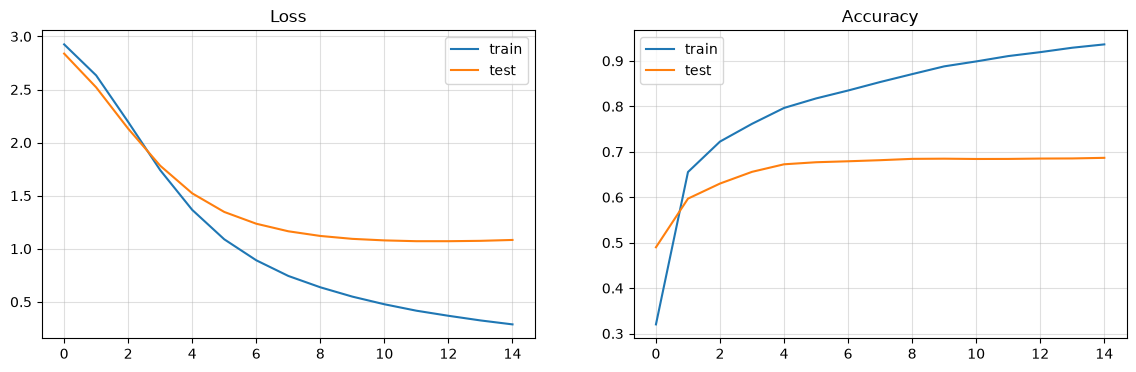

In [16]:
def model_and_opt_from_params(p, input_dim):
    hidden = [p[f"units_l{i}"] for i in range(p["n_layers"])]
    model = MLP(input_dim, NUM_CLASSES, hidden, p["activation"], p["dropout"])
    if p["optimizer"] == "adam":
        kw = dict(beta1=p["beta1"], beta2=p["beta2"])
    elif p["optimizer"] == "rmsprop":
        kw = dict(alpha=p["alpha"], momentum=p["rms_momentum"])
    else:
        kw = dict(momentum=p["sgd_momentum"], nesterov=p["nesterov"])
    opt = build_optimizer(p["optimizer"], model.parameters(), p["lr"], p["weight_decay"], **kw)
    return model, opt

best = study_mlp.best_params
ngram = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
train_texts, test_texts = preprocessed_cache[(best["remove_stopwords"], best["normalization"])]
X_train, X_test, _ = vectorize_data(train_texts, test_texts, ngram, best["max_features"], best["min_df"])

train_loader = DataLoader(to_tensor_dataset(X_train, newsgroups_train.target),
                          batch_size=best["batch_size"], shuffle=True)
test_loader = DataLoader(to_tensor_dataset(X_test, newsgroups_test.target),
                         batch_size=best["batch_size"], shuffle=False)

torch.manual_seed(SEED)
model_final, opt_final = model_and_opt_from_params(best, X_train.shape[1])

t0 = time.time()
writer_final = SummaryWriter(f"{TB_DIR}/mlp_final")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({k: v for k, v in best.items()})
    hist_final = train_mlp(model_final, train_loader, test_loader, opt_final, epochs=15,
                           writer=writer_final, run_name="mlp_final", log_mlflow=True)
t_final = time.time() - t0

model_final.eval()
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.extend(model_final(xb.to(device)).argmax(1).cpu().numpy())
        labels.extend(yb.numpy())

MLP_TEST_ACC = accuracy_score(labels, preds)
print(f"MLP     - test acc: {MLP_TEST_ACC:.4f} | tiempo: {t_final:.1f}s")
writer_final.add_scalar("final/test_acc", MLP_TEST_ACC, 15); writer_final.close()
with mlflow.start_run(run_name="mlp_final_test"):
    mlflow.log_metrics({"test_acc": MLP_TEST_ACC, "tiempo_s": t_final})
print(f"Softmax - test acc: {SOFTMAX_TEST_ACC:.4f}")
print(classification_report(labels, preds, target_names=class_names))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.plot(hist_final["train_loss"], label="train"); a1.plot(hist_final["val_loss"], label="test")
a1.set_title("Loss"); a1.legend(); a1.grid(alpha=.4)
a2.plot(hist_final["train_acc"], label="train"); a2.plot(hist_final["val_acc"], label="test")
a2.set_title("Accuracy"); a2.legend(); a2.grid(alpha=.4)
plt.show()

### Resultados
- **MLP: 0.6867 de test accuracy** (37.7 s) con una sola semilla. El softmax de referencia es el de la Parte 1 (0.6588, impreso en la celda anterior). La comparación robusta, con 5 semillas y presupuestos iguales (MLP 0.6848 ± 0.0014), está en la sección 8.
- **Validación vs test:** el MLP pierde ~5 puntos entre validación (0.7371) y test (0.6867), y el softmax de la Parte 1 ~6 puntos (0.7194 → 0.6588). Como la caída es similar en los dos, no parece un sobreajuste de la búsqueda del MLP. Una hipótesis plausible es que el split de test de 20 Newsgroups es posterior en el tiempo al de train y por eso es una distribución algo distinta; no lo verificamos.
- **Curvas (descriptivas, calculadas sobre test):** la loss de test baja hasta cerca de la época 11–12 y después queda prácticamente plana (sube muy poco), y el accuracy de test queda plano desde la época ~8, mientras que el de train llega a ~0.94. Hay **sobreajuste leve** incluso en el mejor modelo (brecha train–test grande con test estancado). *Esta observación no se usa para decidir nada*: el número de épocas se elige con validación en la sección 4.b.
- **Por clase:** las más difíciles son `talk.religion.misc` (F1 0.34), `alt.atheism` (0.49) y `talk.politics.misc` (0.52), temas con mucho solapamiento de vocabulario con otras clases. Las mejores son `rec.sport.hockey` (0.89) y `rec.sport.baseball` (0.83).


### 4.b. Elección del número de épocas con validación

El entrenamiento final usa 15 épocas, el mismo presupuesto de la búsqueda. Para justificarlo sin mirar el test, se entrena la mejor configuración hasta **30 épocas sobre el split train/validación** y se comparan: la época del mínimo de *val loss*, la de máxima *val accuracy*, y la val accuracy en la época 15. El error estándar de la validación (≈ ±0.9 puntos) fija cuánto debe diferir para considerarlo una diferencia real.

Mínimo de val loss: época 17 (val loss 0.8845, val acc 0.7362)
Máxima val acc:     época 13 (val acc 0.7371)
Val acc en la época 15: 0.7366 | val loss 0.8878
Error estándar de la validación: ±0.0093


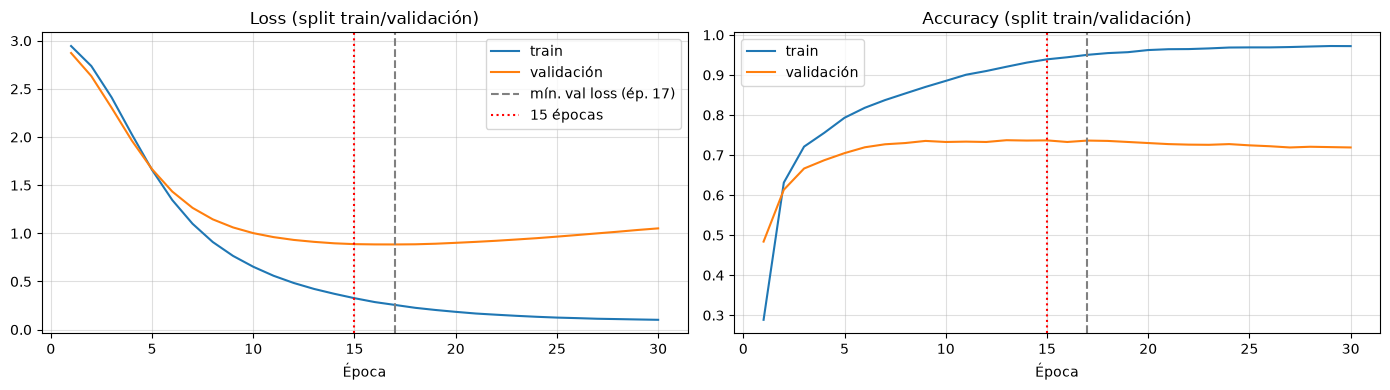

**Resultado:** el mínimo de val loss ocurre en la época **17**, y la val accuracy máxima en la época 13. La val accuracy en la época 15 (0.7366) difiere 0.0 puntos de la de la época del mínimo de loss (0.7362) y 0.0 puntos de la máxima (0.7371); el error estándar es de ±0.9 puntos. **Las 15 épocas se justifican:** la accuracy no cambia de forma apreciable aunque la loss de validación suba después de su mínimo (el modelo se vuelve más confiado en las predicciones erróneas sin cambiar el `argmax`). Se mantiene 15 también para comparar con el mismo presupuesto del resto del TP.

In [17]:
EPOCHS_SEL = 30
best_p = study_mlp.best_params
ng_sel = (1, 1) if best_p["ngram_range"] == "1gram" else (1, 2)
X_tr_s, X_val_s, y_tr_s, y_val_s = get_split_features(
    best_p["remove_stopwords"], best_p["normalization"], ng_sel, best_p["max_features"], best_p["min_df"])
sel_tr = DataLoader(to_tensor_dataset(X_tr_s, y_tr_s), batch_size=best_p["batch_size"], shuffle=True)
sel_val = DataLoader(to_tensor_dataset(X_val_s, y_val_s), batch_size=best_p["batch_size"])

torch.manual_seed(SEED)
m_sel, o_sel = model_and_opt_from_params(best_p, X_tr_s.shape[1])
writer_sel = SummaryWriter(f"{TB_DIR}/seleccion_epocas")
with mlflow.start_run(run_name="seleccion_epocas"):
    h_sel = train_mlp(m_sel, sel_tr, sel_val, o_sel, EPOCHS_SEL, writer=writer_sel, run_name="seleccion", log_mlflow=True)
writer_sel.close()

ep_loss = int(np.argmin(h_sel["val_loss"])) + 1
ep_acc = int(np.argmax(h_sel["val_acc"])) + 1
acc15, acc_loss, acc_max = h_sel["val_acc"][14], h_sel["val_acc"][ep_loss - 1], max(h_sel["val_acc"])
SE_V = (acc15 * (1 - acc15) / len(y_val_s)) ** 0.5
print(f"Mínimo de val loss: época {ep_loss} (val loss {min(h_sel['val_loss']):.4f}, val acc {acc_loss:.4f})")
print(f"Máxima val acc:     época {ep_acc} (val acc {acc_max:.4f})")
print(f"Val acc en la época 15: {acc15:.4f} | val loss {h_sel['val_loss'][14]:.4f}")
print(f"Error estándar de la validación: ±{SE_V:.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
ep = range(1, EPOCHS_SEL + 1)
a1.plot(ep, h_sel["train_loss"], label="train"); a1.plot(ep, h_sel["val_loss"], label="validación")
a1.axvline(ep_loss, color="gray", ls="--", label=f"mín. val loss (ép. {ep_loss})"); a1.axvline(15, color="red", ls=":", label="15 épocas")
a1.set_title("Loss (split train/validación)"); a1.set_xlabel("Época"); a1.legend(); a1.grid(alpha=.4)
a2.plot(ep, h_sel["train_acc"], label="train"); a2.plot(ep, h_sel["val_acc"], label="validación")
a2.axvline(ep_loss, color="gray", ls="--"); a2.axvline(15, color="red", ls=":")
a2.set_title("Accuracy (split train/validación)"); a2.set_xlabel("Época"); a2.legend(); a2.grid(alpha=.4)
plt.tight_layout(); plt.savefig("figures/tp2_seleccion_epocas.png", dpi=150); plt.show()

dentro = abs(acc15 - acc_max) <= SE_V and abs(acc15 - acc_loss) <= SE_V
display(Markdown(
    f"**Resultado:** el mínimo de val loss ocurre en la época **{ep_loss}**, y la val accuracy máxima en la época {ep_acc}. "
    f"La val accuracy en la época 15 ({acc15:.4f}) difiere {abs(acc15 - acc_loss) * 100:.1f} puntos de la de la época del mínimo de loss ({acc_loss:.4f}) y "
    f"{abs(acc15 - acc_max) * 100:.1f} puntos de la máxima ({acc_max:.4f}); el error estándar es de ±{SE_V * 100:.1f} puntos. "
    + ("**Las 15 épocas se justifican:** la accuracy no cambia de forma apreciable aunque la loss de validación suba después de su mínimo "
       "(el modelo se vuelve más confiado en las predicciones erróneas sin cambiar el `argmax`). Se mantiene 15 también para comparar con el mismo presupuesto del resto del TP."
       if dentro else
       f"**La diferencia supera el error estándar**: con early stopping en la época {ep_loss} se obtendría una accuracy distinta; las 15 épocas se mantienen solo para igualar el presupuesto de la búsqueda y de la comparación con softmax, y esta diferencia debe tenerse presente al interpretar el resultado.")))

## 5.Experimento de overfitting

Se entrenan 5 redes de capacidad creciente (1×64, 1×512, 2×512, 3×1024, 3×2048) **sin dropout ni weight decay** (Adam, lr 1e-3, ReLU, 30 épocas) sobre el split train/validación, para ver cómo crece la brecha con la capacidad. Luego se verifica cuál es el máximo de train accuracy alcanzable contando los documentos cuyo vector TF-IDF es idéntico pero tienen etiquetas distintas.

1x64     params=   641,364 train_acc=0.973 val_acc=0.724 best_val_loss_epoch=14 tiempo=30s
1x512    params= 5,130,772 train_acc=0.972 val_acc=0.720 best_val_loss_epoch=6 tiempo=155s
2x512    params= 5,393,428 train_acc=0.973 val_acc=0.685 best_val_loss_epoch=2 tiempo=162s
3x1024   params=12,360,724 train_acc=0.973 val_acc=0.649 best_val_loss_epoch=2 tiempo=357s
3x2048   params=28,915,732 train_acc=0.973 val_acc=0.639 best_val_loss_epoch=2 tiempo=942s


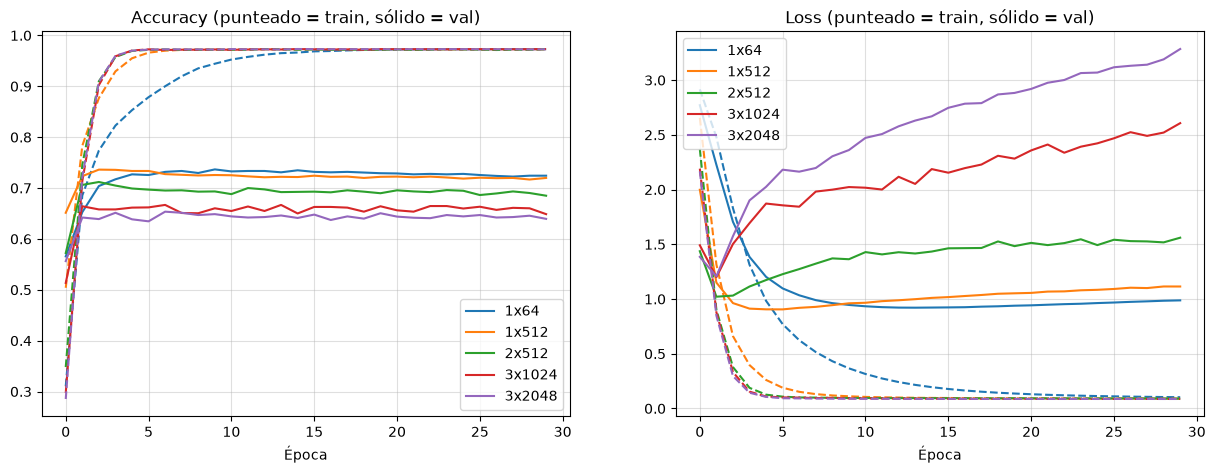

In [18]:
# Datos: mismo preprocesamiento del mejor trial, split train/val
X_tr, X_val, y_tr, y_val = get_split_features(
    best["remove_stopwords"], best["normalization"], ngram, best["max_features"], best["min_df"])
of_train = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=128, shuffle=True)
of_val = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=128)

OVERFIT_CONFIGS = {
    "1x64":           [64],
    "1x512":          [512],
    "2x512":          [512, 512],
    "3x1024":         [1024, 1024, 1024],
    "3x2048":         [2048, 2048, 2048],
}
EPOCHS_OF = 30
of_results = {}

for name, hidden in OVERFIT_CONFIGS.items():
    torch.manual_seed(SEED)
    m = MLP(X_tr.shape[1], NUM_CLASSES, hidden, activation="relu", dropout=0.0)
    o = build_optimizer("adam", m.parameters(), lr=1e-3, weight_decay=0.0)
    t0 = time.time()
    h = train_mlp(m, of_train, of_val, o, EPOCHS_OF)
    of_results[name] = dict(hist=h, time=time.time() - t0,
                            n_params=sum(p.numel() for p in m.parameters()))
    print(f"{name:8s} params={of_results[name]['n_params']:>10,d} "
          f"train_acc={h['train_acc'][-1]:.3f} val_acc={h['val_acc'][-1]:.3f} "
          f"best_val_loss_epoch={int(np.argmin(h['val_loss']))+1} "
          f"tiempo={of_results[name]['time']:.0f}s")

# Curvas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, r in of_results.items():
    l, = axes[0].plot(r["hist"]["train_acc"], linestyle="--")
    axes[0].plot(r["hist"]["val_acc"], color=l.get_color(), label=name)
    l, = axes[1].plot(r["hist"]["train_loss"], linestyle="--")
    axes[1].plot(r["hist"]["val_loss"], color=l.get_color(), label=name)
axes[0].set_title("Accuracy (punteado = train, sólido = val)")
axes[1].set_title("Loss (punteado = train, sólido = val)")
for a in axes: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.4)
plt.show()

In [19]:
from collections import Counter, defaultdict

X = X_tr.tocsr(); X.sort_indices()
groups = defaultdict(list)
for i in range(X.shape[0]):
    s, e = X.indptr[i], X.indptr[i + 1]
    key = (X.indices[s:e].tobytes(), X.data[s:e].round(6).tobytes())
    groups[key].append(y_tr[i])

# Mínimo de errores inevitables: en cada grupo de vectores idénticos solo se puede acertar la etiqueta mayoritaria
unfit = sum(len(v) - Counter(v).most_common(1)[0][1] for v in groups.values())
vacios = sum(len(v) for k, v in groups.items() if len(k[0]) == 0)
print(f"Docs con vector vacío: {vacios} | errores inevitables >= {unfit} "
      f"-> techo de train acc <= {1 - unfit / X.shape[0]:.3f}")

Docs con vector vacío: 262 | errores inevitables >= 241 -> techo de train acc <= 0.973


### Resultados
| Config | Parámetros | Tiempo | Train acc | Val acc | Brecha | Época del mínimo de val loss | Val loss final |
|---|---|---|---|---|---|---|---|
| 1×64 | 0.64 M | 30 s | 0.973 | 0.724 | 0.25 | 14 | 0.99 |
| 1×512 | 5.1 M | 155 s | 0.972 | 0.720 | 0.25 | 6 | 1.11 |
| 2×512 | 5.4 M | 162 s | 0.973 | 0.685 | 0.29 | 2 | 1.56 |
| 3×1024 | 12.4 M | 357 s | 0.973 | 0.649 | 0.32 | 2 | 2.61 |
| 3×2048 | 28.9 M | 942 s | 0.973 | 0.639 | 0.33 | 2 | 3.28 |

- **Las configuraciones 3×1024 y 3×2048 cumplen la consigna**: train accuracy en el techo, val accuracy ~0.64–0.65 y val loss que crece de forma sostenida desde la época 2.
- **El problema se sobreajusta con muy poca capacidad**: incluso 1×64 llega a train acc 0.973.
- **0.973 es el techo alcanzable.** Hay 262 documentos con vector vacío (quedaron sin texto tras eliminar headers, footers y quotes) y al menos 241 errores inevitables entre documentos con vectores idénticos y etiquetas distintas, lo que acota la train accuracy a ≤ 0.973. Las cinco redes lo alcanzan: **memorizaron todo lo memorizable**.
- **Más capacidad no mejora la validación y empeora la loss.** No afirmamos que 3×1024 sea mejor que 3×2048 (0.649 vs 0.639): está dentro del ruido y las curvas oscilan.
- **Costo:** de 1×64 a 3×2048 los parámetros se multiplican por ~45 y el tiempo por ~31, con la val accuracy bajando.


## 6. Análisis de todos los trials

Se construye una tabla con todos los trials (completos y podados) y se analizan: importancia de hiperparámetros, historia de la optimización, rendimiento por optimizador, activación y profundidad, relación tiempo–accuracy y efecto del pruning.

C:\Users\matia\AppData\Local\Temp\ipykernel_2728\3209506538.py:25: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_param_importances(study_mlp))
c:\Users\matia\AppData\Local\Programs\Python\Python312\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `sgd_momentum` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(
c:\Users\matia\AppData\Local\Programs\Python\Python312\Lib\site-packages\optuna\importance\_ped_anova\evaluator.py:353: UserWarning: Some regimes for parameter `nesterov` have less than 2 trials. The importance of the parameter may be inaccurate.
  optuna_warn(


<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

C:\Users\matia\AppData\Local\Temp\ipykernel_2728\3209506538.py:26: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  display(vis.plot_optimization_history(study_mlp))


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>


=== Por optimizer ===
           n_trials  pct_podados  n_completos  val_media  val_max  \
optimizer                                                           
adam             48        0.354           31      0.666    0.737   
rmsprop           3        0.000            3      0.545    0.571   
sgd               9        0.889            1      0.053    0.053   

           dur_media_s  gap_medio  
optimizer                          
adam            57.724      0.272  
rmsprop         79.271      0.312  
sgd             40.193     -0.003  

=== Por activation ===
            n_trials  pct_podados  n_completos  val_media  val_max  \
activation                                                           
elu               41         0.39         25.0      0.657    0.737   
gelu               5         0.60          2.0      0.312    0.571   
leaky_relu         4         0.50          2.0      0.671    0.730   
relu               2         1.00          NaN        NaN      NaN   
tanh   

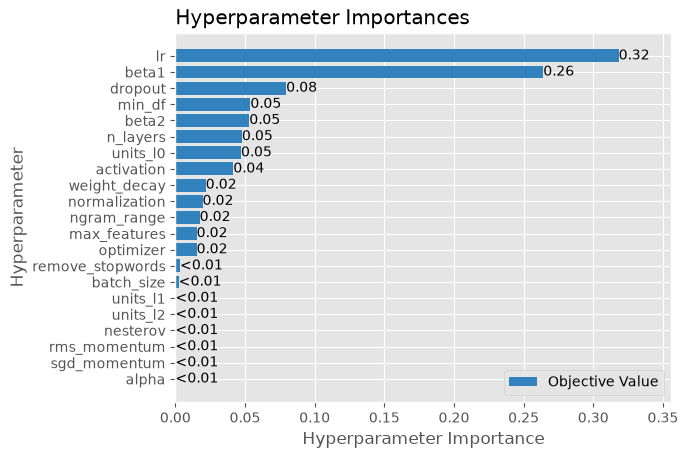

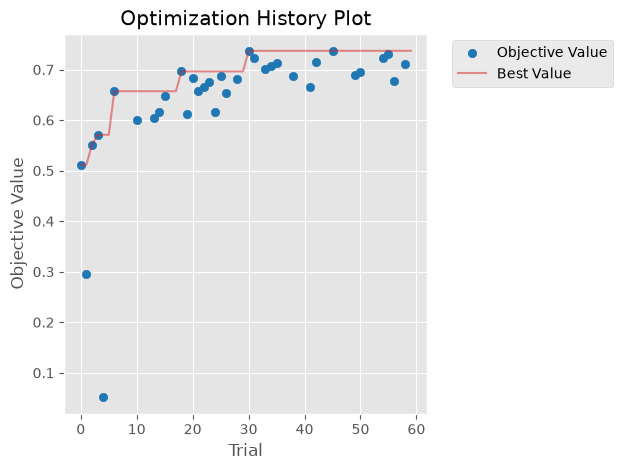

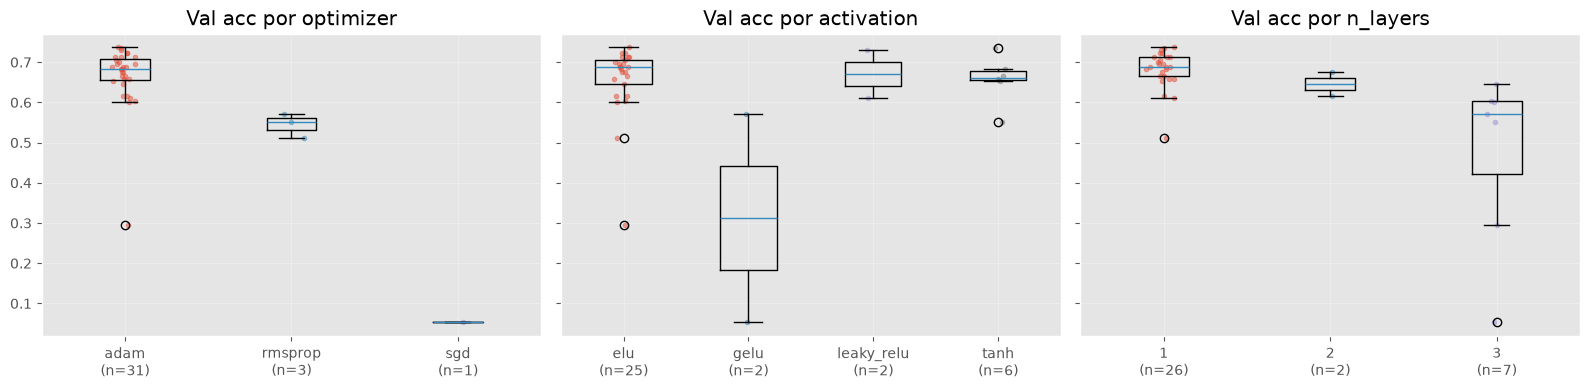

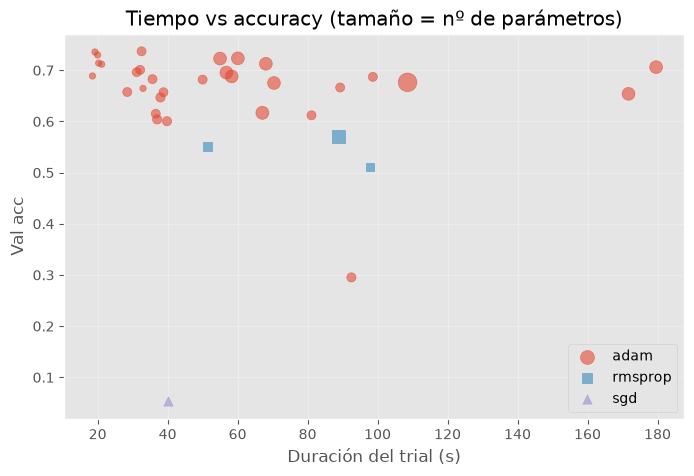

Completos: 35 | tiempo total 34.5 min
Podados:   25 | tiempo total 5.9 min
Sin pruning (estimación gruesa, cada trial = mediana de completos): 50.0 min
          count  mean  std   min   25%   50%   75%   max
state                                                   
COMPLETE   35.0  15.0  0.0  15.0  15.0  15.0  15.0  15.0
PRUNED     25.0   4.0  0.2   4.0   4.0   4.0   4.0   5.0
            params  train_acc  val_acc    gap  val_loss_min  epoca_min  \
1x64      641364.0      0.973    0.724  0.249         0.921       14.0   
1x512    5130772.0      0.972    0.720  0.253         0.905        6.0   
2x512    5393428.0      0.973    0.685  0.288         1.021        2.0   
3x1024  12360724.0      0.973    0.649  0.324         1.200        2.0   
3x2048  28915732.0      0.973    0.639  0.333         1.207        2.0   

        val_loss_final  tiempo_s  
1x64             0.988    29.808  
1x512            1.114   154.546  
2x512            1.560   161.528  
3x1024           2.607   356.766  


In [20]:
import pandas as pd

def study_to_df(st):
    rows = []
    for t in st.trials:
        ivs = t.intermediate_values
        rows.append(dict(
            number=t.number, state=t.state.name, val_acc=t.value,
            last_val_acc=ivs[max(ivs)] if ivs else np.nan,
            epochs_run=len(ivs),
            dur=t.duration.total_seconds() if t.duration else np.nan,
            n_params=t.user_attrs.get("n_params"),
            train_acc=t.user_attrs.get("final_train_acc"),
            **{k: t.params.get(k) for k in
               ["optimizer", "activation", "n_layers", "lr", "dropout",
                "weight_decay", "max_features", "ngram_range", "batch_size"]}))
    return pd.DataFrame(rows)

df = study_to_df(study_mlp)
done = df[df.state == "COMPLETE"].copy()
pruned = df[df.state == "PRUNED"]
done["gap"] = done.train_acc - done.val_acc

# --- 1. Importancia de HPs e historia de optimización ---
display(vis.plot_param_importances(study_mlp))
display(vis.plot_optimization_history(study_mlp))

# --- 2. Tablas por optimizador / activación / profundidad ---
for col in ["optimizer", "activation", "n_layers"]:
    a = df.groupby(col).agg(n_trials=("state", "size"),
                            pct_podados=("state", lambda s: (s == "PRUNED").mean()))
    b = done.groupby(col).agg(n_completos=("val_acc", "size"), val_media=("val_acc", "mean"),
                              val_max=("val_acc", "max"), dur_media_s=("dur", "mean"),
                              gap_medio=("gap", "mean"))
    print(f"\n=== Por {col} ===")
    print(a.join(b).round(3))

# --- 3. Boxplots (con n visible) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["optimizer", "activation", "n_layers"]):
    gs = sorted(done[col].unique())
    data = [done[done[col] == g].val_acc.values for g in gs]
    ax.boxplot(data)
    for i, d in enumerate(data, 1):
        ax.scatter(np.random.normal(i, 0.04, len(d)), d, alpha=.5, s=12)
    ax.set_xticks(range(1, len(gs) + 1))
    ax.set_xticklabels([f"{g}\n(n={len(d)})" for g, d in zip(gs, data)])
    ax.set_title(f"Val acc por {col}"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# --- 4. Tiempo vs accuracy ---
plt.figure(figsize=(8, 5))
for opt, mk in {"adam": "o", "rmsprop": "s", "sgd": "^"}.items():
    d = done[done.optimizer == opt]
    plt.scatter(d.dur, d.val_acc, marker=mk, s=d.n_params / 30000, alpha=.6, label=opt)
plt.xlabel("Duración del trial (s)"); plt.ylabel("Val acc")
plt.title("Tiempo vs accuracy (tamaño = nº de parámetros)")
plt.legend(); plt.grid(alpha=.3); plt.show()

# --- 5. Efecto del pruning ---
med = done.dur.median()
print(f"Completos: {len(done)} | tiempo total {done.dur.sum()/60:.1f} min")
print(f"Podados:   {len(pruned)} | tiempo total {pruned.dur.sum()/60:.1f} min")
print(f"Sin pruning (estimación gruesa, cada trial = mediana de completos): "
      f"{len(df) * med / 60:.1f} min")
print(df.groupby("state").epochs_run.describe().round(1))

# --- 6. Resumen del experimento de overfitting ---
of_df = pd.DataFrame({n: dict(
    params=r["n_params"], train_acc=r["hist"]["train_acc"][-1], val_acc=r["hist"]["val_acc"][-1],
    gap=r["hist"]["train_acc"][-1] - r["hist"]["val_acc"][-1],
    val_loss_min=min(r["hist"]["val_loss"]), epoca_min=int(np.argmin(r["hist"]["val_loss"])) + 1,
    val_loss_final=r["hist"]["val_loss"][-1], tiempo_s=r["time"])
    for n, r in of_results.items()}).T
print(of_df.round(3))

### Conclusiones
**Limitación importante:** TPE concentra los trials en la zona buena, así que los grupos quedan muy desbalanceados y confundidos con otros hiperparámetros. Por eso los boxplots **no sirven para comparar** factores: hay 48 trials de Adam, 3 de RMSprop y 9 de SGD (de los cuales solo **1** completó); 41 de ELU contra 2–8 del resto de las activaciones; 46 trials de 1 capa contra 5 de 2 capas y 9 de 3 capas (estos incluyen configuraciones que fallaron por su lr, no por la profundidad). Esas comparaciones se hacen con experimentos controlados (3.b, 6.b y 7).

**Lo que sí se observa:**
- **Importancia de HPs:** el learning rate y el dropout aparecen entre los más relevantes. La importancia de `alpha` y `rms_momentum` es alta pero se estima solo sobre los trials RMSprop y está mezclada con el efecto de haber elegido ese optimizador, así que debe tomarse con cautela. Que `optimizer` figure con importancia casi nula no implica que no importe.
- **Tiempo vs accuracy:** en el experimento de la sección 5, 1×512 (5.1 M parámetros) tarda 155 s y rinde igual que 1×64 (0.64 M parámetros, 30 s): 0.720 contra 0.724 de val acc. **Más parámetros no dieron mejor accuracy y costaron ~5 veces más tiempo.**
- **Pruning:** los 25 trials podados consumieron 5.9 min en total, contra 34.5 min de los 35 completos. Sin pruning, estimamos groseramente unos 50 min (suponiendo que cada trial tarda la mediana de los completos), es decir un **ahorro de ~19 %**. Es modesto porque TPE ya evitaba las zonas malas y los trials podados eran baratos.

### 6.b. Análisis de optimizadores

In [21]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
STORAGE = "sqlite:///mlp_study.db"

studies = {name: optuna.load_study(study_name=f"mlp_{name}", storage=STORAGE)
           for name in ["adam", "rmsprop", "sgd"]}
study_mlp = optuna.load_study(study_name="mlp_20newsgroups", storage=STORAGE)

def study_to_df(st):
    rows = []
    for t in st.trials:
        ivs = t.intermediate_values
        rows.append(dict(
            number=t.number, state=t.state.name, val_acc=t.value,
            last_val_acc=ivs[max(ivs)] if ivs else np.nan,
            epochs_run=len(ivs),
            dur=t.duration.total_seconds() if t.duration else np.nan,
            n_params=t.user_attrs.get("n_params"),
            train_acc=t.user_attrs.get("final_train_acc"),
            **{k: t.params.get(k) for k in
               ["optimizer", "activation", "n_layers", "lr", "dropout",
                "weight_decay", "max_features", "ngram_range", "batch_size"]}))
    return pd.DataFrame(rows)

for n, st in studies.items():
    print(n, "->", sum(t.state.name in ("COMPLETE", "PRUNED") for t in st.trials), "trials terminados",
          f"({sum(t.state.name == 'FAIL' for t in st.trials)} fallidos)" if any(t.state.name == "FAIL" for t in st.trials) else "")

adam -> 20 trials terminados 
rmsprop -> 20 trials terminados 
sgd -> 20 trials terminados 


optimizador  trials  completos  podados  val_max  val_mediana  dur_completos_s  dur_podados_s
       adam      20         14        6   0.7406       0.7139          25.1831        12.0173
    rmsprop      20          9       11   0.7366       0.7176          25.3285         7.0954
        sgd      20         11        9   0.6986       0.6589          43.8151        15.8848


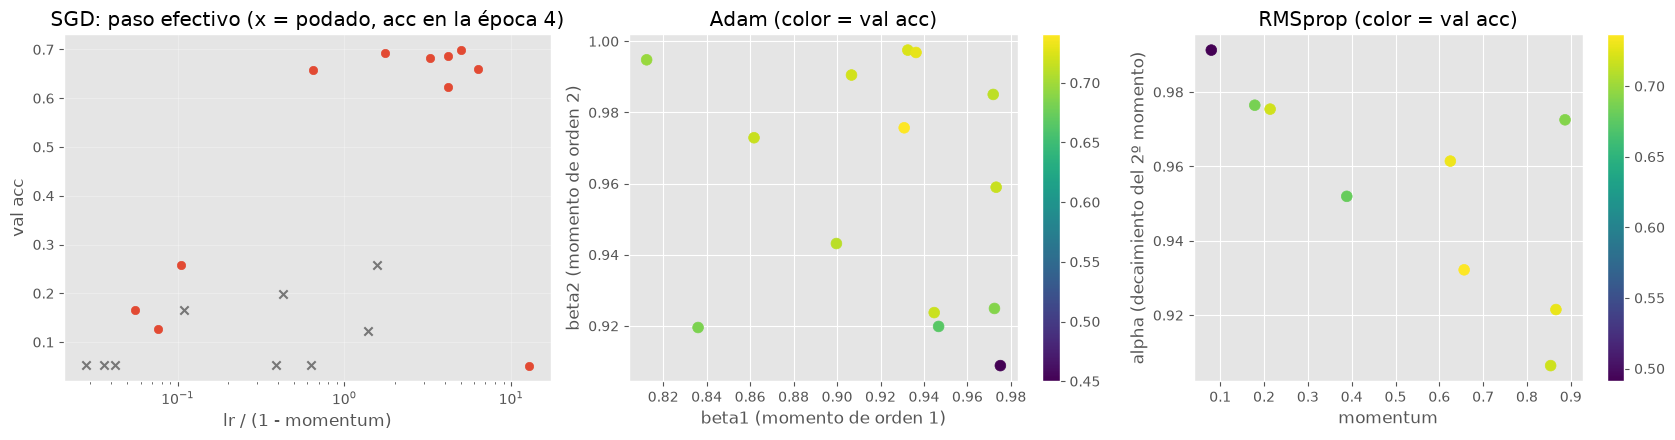

In [22]:
# --- Resumen por optimizador ---
rows = []
for name, st in studies.items():
    d = study_to_df(st)
    d = d[d.state.isin(["COMPLETE", "PRUNED"])]      # se excluye el trial interrumpido (FAIL)
    dd, pp = d[d.state == "COMPLETE"], d[d.state == "PRUNED"]
    rows.append(dict(optimizador=name, trials=len(d), completos=len(dd), podados=len(pp),
                     val_max=dd.val_acc.max(), val_mediana=dd.val_acc.median(),
                     dur_completos_s=dd.dur.mean(), dur_podados_s=pp.dur.mean()))
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- Hiperparámetros propios de cada optimizador ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# SGD: paso efectivo lr/(1-momentum)
for t in studies["sgd"].trials:
    if "sgd_momentum" not in t.params:
        continue
    eff = t.params["lr"] / (1 - t.params["sgd_momentum"])
    if t.state.name == "COMPLETE":
        ax[0].scatter(eff, t.value, c="C0")
    elif t.state.name == "PRUNED" and t.intermediate_values:   # podado: accuracy en la última época medida
        ax[0].scatter(eff, t.intermediate_values[max(t.intermediate_values)], marker="x", c="C3")
ax[0].set_xscale("log"); ax[0].set_xlabel("lr / (1 - momentum)"); ax[0].set_ylabel("val acc")
ax[0].set_title("SGD: paso efectivo (x = podado, acc en la época 4)"); ax[0].grid(alpha=.3)

# Adam: momentos de orden 1 y 2
ts = [t for t in studies["adam"].trials if t.state.name == "COMPLETE"]
sc = ax[1].scatter([t.params["beta1"] for t in ts], [t.params["beta2"] for t in ts],
                   c=[t.value for t in ts], cmap="viridis", s=60)
ax[1].set_xlabel("beta1 (momento de orden 1)"); ax[1].set_ylabel("beta2 (momento de orden 2)")
ax[1].set_title("Adam (color = val acc)"); plt.colorbar(sc, ax=ax[1])

# RMSprop: alpha (orden 2) y momentum (orden 1)
ts = [t for t in studies["rmsprop"].trials if t.state.name == "COMPLETE"]
sc = ax[2].scatter([t.params["rms_momentum"] for t in ts], [t.params["alpha"] for t in ts],
                   c=[t.value for t in ts], cmap="viridis", s=60)
ax[2].set_xlabel("momentum"); ax[2].set_ylabel("alpha (decaimiento del 2º momento)")
ax[2].set_title("RMSprop (color = val acc)"); plt.colorbar(sc, ax=ax[2])
plt.tight_layout(); plt.show()

In [23]:
SE_VAL = (0.7 * 0.3 / 2263) ** 0.5
filas = ["| | Trials terminados | Mejor val | Mediana val | Podados | Duración completos | Duración podados |", "|---|---|---|---|---|---|---|"]
pct_pod = {}
sgd_info = None
for name, st in studies.items():
    d = study_to_df(st); d = d[d.state.isin(["COMPLETE", "PRUNED"])]
    dd, pp = d[d.state == "COMPLETE"], d[d.state == "PRUNED"]
    pct_pod[name] = len(pp) / len(d)
    filas.append(f"| {name} | {len(d)} | {dd.val_acc.max():.4f} | {dd.val_acc.median():.3f} | {len(pp)}/{len(d)} | {dd.dur.mean():.0f} s | {pp.dur.mean():.0f} s |")
display(Markdown("\n".join(filas)))

# ---- SGD: paso efectivo lr / (1 - momentum) ----
ts = [t for t in studies["sgd"].trials if t.state.name == "COMPLETE" and "sgd_momentum" in t.params]
eff = pd.DataFrame([dict(paso=t.params["lr"] / (1 - t.params["sgd_momentum"]), val=t.value) for t in ts])
buenos, malos = eff[eff.val >= 0.60], eff[eff.val < 0.30]
medios = eff[(eff.val >= 0.30) & (eff.val < 0.60)]
def mediana_completos(name):
    dd_ = study_to_df(studies[name])
    return dd_[dd_.state == "COMPLETE"].val_acc.median()
texto = (f"- **SGD es mucho más sensible.** Mediana de val acc de SGD: {eff.val.median():.3f} "
         f"(Adam {mediana_completos('adam'):.3f}, RMSprop {mediana_completos('rmsprop'):.3f}). ")
if len(buenos):
    texto += f"Los {len(buenos)} trials completos con val acc ≥ 0.60 tuvieron un **paso efectivo** `lr/(1−momentum)` entre {buenos.paso.min():.2f} y {buenos.paso.max():.2f}. "
if len(malos):
    texto += f"Los {len(malos)} con val acc < 0.30 tuvieron un paso efectivo entre {malos.paso.min():.3f} y {malos.paso.max():.2f}. "
texto += "Son pocos puntos y confundidos con otros hiperparámetros, así que es un patrón coherente y no una prueba.\n"
pmin, pmax = min(pct_pod.values()), max(pct_pod.values())
texto += f"- **Pruning:** descartó entre el {pmin:.0%} y el {pmax:.0%} de los trials según el optimizador."
display(Markdown(texto))

| | Trials terminados | Mejor val | Mediana val | Podados | Duración completos | Duración podados |
|---|---|---|---|---|---|---|
| adam | 20 | 0.7406 | 0.714 | 6/20 | 25 s | 12 s |
| rmsprop | 20 | 0.7366 | 0.718 | 11/20 | 25 s | 7 s |
| sgd | 20 | 0.6986 | 0.659 | 9/20 | 44 s | 16 s |

- **SGD es mucho más sensible.** Mediana de val acc de SGD: 0.659 (Adam 0.714, RMSprop 0.718). Los 7 trials completos con val acc ≥ 0.60 tuvieron un **paso efectivo** `lr/(1−momentum)` entre 0.65 y 6.29. Los 4 con val acc < 0.30 tuvieron un paso efectivo entre 0.056 y 12.72. Son pocos puntos y confundidos con otros hiperparámetros, así que es un patrón coherente y no una prueba.
- **Pruning:** descartó entre el 30% y el 55% de los trials según el optimizador.

- **Adam y RMSprop** rinden igual y toleran casi todo el rango de lr explorado, con medianas de ~0.71 (0.714 y 0.718).
- **Momentos de orden 1 y 2:** en el rango explorado no se ve un patrón claro respecto de β1 ni β2 en Adam. En RMSprop el mejor trial usó α ≈ 0.93 y momentum ≈ 0.66, pero con solo 20 trials y dependiendo de dónde TPE concentró la búsqueda, **la búsqueda no permite aislar el efecto de los momentos.**
- **Tiempo:** el costo lo domina el **ancho de la primera capa** (10000 × unidades), no el optimizador. En la sección 5, 1×64 tarda 30 s y 1×512 155 s. Las diferencias de duración media entre optimizadores de la tabla (25 s Adam y RMSprop, 44 s SGD en los trials completos) se explican sobre todo por las arquitecturas que TPE eligió para cada uno (SGD eligió 512 unidades en su mejor trial).


### 6.c. Efecto aislado de dropout y weight decay (experimento controlado)

En la búsqueda de Optuna dropout y weight decay varían junto con todo lo demás, así que su efecto individual no se puede leer. Acá se parte de la **mejor configuración** (arquitectura, optimizador, lr y preprocesamiento del mejor trial) y se cambia **un solo factor por vez**, con 2 semillas, sobre el split train/validación y 15 épocas:

- **Dropout** ∈ {0, 0.1, 0.3, 0.5} con weight decay = 0.
- **Weight decay (L2 acoplado)** ∈ {0, 1e-6, 1e-5, 1e-4, 1e-3} con dropout = 0.
- Dos alternativas vistas en la clase de regularización, con dropout = 0: **weight decay 1e-4 aplicado solo a los pesos (sin los bias)** y **max-norm** (se restringe la norma de cada fila de pesos de las capas lineales a `c` después de cada paso; `c` se toma como la mediana de las normas de fila del modelo base, de modo que restrinja a la mitad de las unidades).

**Marco teórico.** *L2 / weight decay* agrega `λ‖w‖²` a la loss y empuja los pesos hacia cero (menor varianza, algo de sesgo). Con optimizadores adaptativos como Adam/RMSprop, el L2 "acoplado" que usa `weight_decay` se mezcla con la normalización por la varianza del gradiente; la variante *desacoplada* (AdamW) evita ese efecto. Normalmente **no se regularizan los bias**: no controlan la complejidad de la función y penalizarlos solo agrega sesgo. *Dropout* apaga unidades al azar en cada paso, lo que evita la co-adaptación y se interpreta como un promedio de muchas subredes; con "inverted dropout" (PyTorch) la escala se corrige en entrenamiento. *Max-norm* acota directamente la norma de los pesos de entrada de cada unidad, lo que permite usar lr altos sin que los pesos crezcan sin control.

base (sin dropout, sin wd)         val 0.7355 | train 0.9601 | brecha 0.225
dropout=0.1                        val 0.7393 | train 0.9556 | brecha 0.216
dropout=0.3                        val 0.7411 | train 0.9427 | brecha 0.202
dropout=0.5                        val 0.7406 | train 0.9187 | brecha 0.178
weight_decay=1e-06                 val 0.7335 | train 0.9601 | brecha 0.227
weight_decay=1e-05                 val 0.7329 | train 0.9591 | brecha 0.226
weight_decay=0.0001                val 0.7304 | train 0.9528 | brecha 0.222
weight_decay=0.001                 val 0.7110 | train 0.8750 | brecha 0.164
wd=1e-4 solo en pesos (sin bias)   val 0.7304 | train 0.9528 | brecha 0.222
max-norm (c=8.85)                  val 0.7353 | train 0.9600 | brecha 0.225


,grupo,val_acc,val_std,train_acc,brecha,val_loss_min,val_loss_final
config,,,,,,,
"base (sin dropout, sin wd)",base,0.7355,0.0011,0.9601,0.2245,0.8890,0.8935
dropout=0.1,dropout,0.7393,0.0000,0.9556,0.2164,0.8886,0.8901
dropout=0.3,dropout,0.7411,0.0004,0.9427,0.2016,0.8882,0.8882
dropout=0.5,dropout,0.7406,0.0027,0.9187,0.1781,0.9039,0.9039
weight_decay=1e-06,weight decay,0.7335,0.0009,0.9601,0.2265,0.8919,0.8967
weight_decay=1e-05,weight decay,0.7329,0.0002,0.9591,0.2262,0.9045,0.9089
weight_decay=0.0001,weight decay,0.7304,0.0018,0.9528,0.2223,0.9642,0.9646
weight_decay=0.001,weight decay,0.7110,0.0013,0.8750,0.1640,1.2208,1.2208
wd=1e-4 solo en pesos (sin bias),alternativas,0.7304,0.0018,0.9528,0.2223,0.9642,0.9646


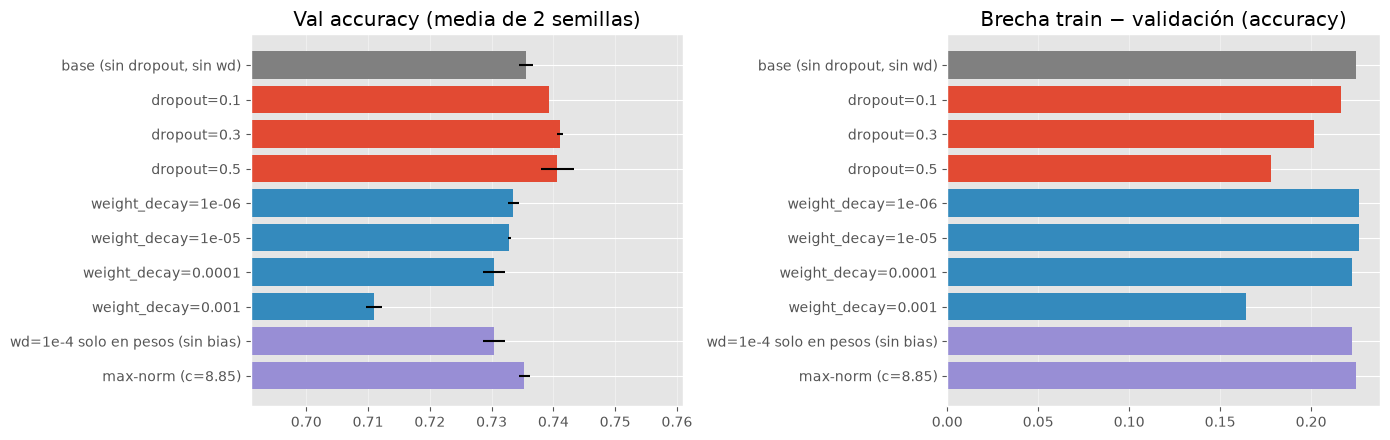

- **Base** sin regularizar: val acc 0.7355, brecha train−val 22.5 puntos, val loss mínima 0.889 y final 0.893.
- **Dropout:** el mejor valor fue dropout=0.3 (val acc 0.7411, +0.6 puntos vs base; brecha 20.2 puntos). Al subir el dropout de 0.1 a 0.5 la brecha train−val pasa de 21.6 a 17.8 puntos.
- **Weight decay:** el mejor valor fue weight_decay=1e-06 (val acc 0.7335, -0.2 puntos vs base). Valores grandes (1e-3) degradan la accuracy (0.7110).
- **Sin decay en los bias (wd=1e-4):** val acc 0.7304 contra 0.7304 aplicándolo a todo (+0.0 puntos).
- **Max-norm (c=8.85):** val acc 0.7353 (-0.0 puntos vs base), brecha 22.5 puntos.
- Con 2 semillas y un error estándar de la validación de ≈ ±1.0 puntos, **solo diferencias claramente mayores a eso son interpretables**.

In [24]:
def build_optimizer_groups(name, model, lr, wd, wd_on_bias=True, **kw):
    # wd_on_bias=False: el weight decay se aplica solo a los pesos (tensores con ndim > 1), no a los bias.
    if wd_on_bias:
        return build_optimizer(name, model.parameters(), lr, wd, **kw)
    pesos = [p for p in model.parameters() if p.ndim > 1]
    biases = [p for p in model.parameters() if p.ndim <= 1]
    grupos = [{"params": pesos, "weight_decay": wd}, {"params": biases, "weight_decay": 0.0}]
    return build_optimizer(name, grupos, lr, weight_decay=0.0, **kw)

def make_maxnorm(c):
    def clamp(model):
        with torch.no_grad():
            for m in model.modules():
                if isinstance(m, nn.Linear):
                    n = m.weight.norm(dim=1, keepdim=True).clamp_min(1e-12)
                    m.weight.mul_(torch.clamp(c / n, max=1.0))
    return clamp

bp = study_mlp.best_params
ng_r = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
Xr_tr, Xr_val, yr_tr, yr_val = get_split_features(bp["remove_stopwords"], bp["normalization"], ng_r, bp["max_features"], bp["min_df"])
reg_tr = DataLoader(to_tensor_dataset(Xr_tr, yr_tr), batch_size=bp["batch_size"], shuffle=True)
reg_val = DataLoader(to_tensor_dataset(Xr_val, yr_val), batch_size=bp["batch_size"])
if bp["optimizer"] == "adam":
    opt_kw = dict(beta1=bp["beta1"], beta2=bp["beta2"])
elif bp["optimizer"] == "rmsprop":
    opt_kw = dict(alpha=bp["alpha"], momentum=bp["rms_momentum"])
else:
    opt_kw = dict(momentum=bp["sgd_momentum"], nesterov=bp["nesterov"])
hidden_r = [bp[f"units_l{i}"] for i in range(bp["n_layers"])]
REG_SEEDS = [0, 1]
REG_EPOCHS = 15

def run_reg(dropout, wd, wd_on_bias=True, maxnorm=None, seed=0):
    torch.manual_seed(seed)
    m = MLP(Xr_tr.shape[1], NUM_CLASSES, hidden_r, bp["activation"], dropout)
    o = build_optimizer_groups(bp["optimizer"], m, bp["lr"], wd, wd_on_bias, **opt_kw)
    h = train_mlp(m, reg_tr, reg_val, o, REG_EPOCHS, post_step=make_maxnorm(maxnorm) if maxnorm else None)
    return h, m

# Modelo base (sin regularización) -> también da la escala para max-norm
filas_reg = []
def registrar(nombre, grupo, dropout, wd, **kw):
    accs, tr, vl_min, vl_fin = [], [], [], []
    for sd in REG_SEEDS:
        h, m = run_reg(dropout, wd, seed=sd, **kw)
        accs.append(h["val_acc"][-1]); tr.append(h["train_acc"][-1])
        vl_min.append(min(h["val_loss"])); vl_fin.append(h["val_loss"][-1])
    filas_reg.append(dict(grupo=grupo, config=nombre, val_acc=np.mean(accs), val_std=np.std(accs),
                          train_acc=np.mean(tr), brecha=np.mean(tr) - np.mean(accs),
                          val_loss_min=np.mean(vl_min), val_loss_final=np.mean(vl_fin)))
    print(f"{nombre:34s} val {np.mean(accs):.4f} | train {np.mean(tr):.4f} | brecha {np.mean(tr) - np.mean(accs):.3f}")
    return m

m_base = registrar("base (sin dropout, sin wd)", "base", 0.0, 0.0)
for dp in [0.1, 0.3, 0.5]:
    registrar(f"dropout={dp}", "dropout", dp, 0.0)
for wd in [1e-6, 1e-5, 1e-4, 1e-3]:
    registrar(f"weight_decay={wd:g}", "weight decay", 0.0, wd)
registrar("wd=1e-4 solo en pesos (sin bias)", "alternativas", 0.0, 1e-4, wd_on_bias=False)
c_ref = float(np.median(m_base.net[0].weight.detach().norm(dim=1).cpu().numpy()))
registrar(f"max-norm (c={c_ref:.2f})", "alternativas", 0.0, 0.0, maxnorm=c_ref)

reg_df = pd.DataFrame(filas_reg)
reg_df.to_csv("results/tp2_regularizacion.csv", index=False)
display(reg_df.round(4).set_index("config"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
colores = {"base": "gray", "dropout": "C0", "weight decay": "C1", "alternativas": "C2"}
ax[0].barh(reg_df.config, reg_df.val_acc, xerr=reg_df.val_std, color=[colores[g] for g in reg_df.grupo])
ax[0].set_xlim(reg_df.val_acc.min() - 0.02, reg_df.val_acc.max() + 0.02); ax[0].set_title("Val accuracy (media de 2 semillas)")
ax[1].barh(reg_df.config, reg_df.brecha, color=[colores[g] for g in reg_df.grupo]); ax[1].set_title("Brecha train − validación (accuracy)")
for a in ax: a.grid(axis="x", alpha=.4); a.invert_yaxis()
plt.tight_layout(); plt.savefig("figures/tp2_regularizacion.png", dpi=150); plt.show()

b0 = reg_df.iloc[0]
def fila(c): return reg_df[reg_df.config == c].iloc[0]
dp_rows, wd_rows = reg_df[reg_df.grupo == "dropout"], reg_df[reg_df.grupo == "weight decay"]
mejor_dp, mejor_wd = dp_rows.loc[dp_rows.val_acc.idxmax()], wd_rows.loc[wd_rows.val_acc.idxmax()]
nb_row, mn_row = reg_df[reg_df.config.str.startswith("wd=1e-4 solo")].iloc[0], reg_df[reg_df.config.str.startswith("max-norm")].iloc[0]
wd4 = fila("weight_decay=0.0001")
display(Markdown(
    f"- **Base** sin regularizar: val acc {b0.val_acc:.4f}, brecha train−val {b0.brecha * 100:.1f} puntos, val loss mínima {b0.val_loss_min:.3f} y final {b0.val_loss_final:.3f}.\n"
    f"- **Dropout:** el mejor valor fue {mejor_dp.config} (val acc {mejor_dp.val_acc:.4f}, {(mejor_dp.val_acc - b0.val_acc) * 100:+.1f} puntos vs base; brecha {mejor_dp.brecha * 100:.1f} puntos). "
    f"Al subir el dropout de 0.1 a 0.5 la brecha train−val pasa de {dp_rows.iloc[0].brecha * 100:.1f} a {dp_rows.iloc[-1].brecha * 100:.1f} puntos.\n"
    f"- **Weight decay:** el mejor valor fue {mejor_wd.config} (val acc {mejor_wd.val_acc:.4f}, {(mejor_wd.val_acc - b0.val_acc) * 100:+.1f} puntos vs base). "
    f"Valores grandes (1e-3) {'degradan' if wd_rows.iloc[-1].val_acc < b0.val_acc else 'no degradan'} la accuracy ({wd_rows.iloc[-1].val_acc:.4f}).\n"
    f"- **Sin decay en los bias (wd=1e-4):** val acc {nb_row.val_acc:.4f} contra {wd4.val_acc:.4f} aplicándolo a todo ({(nb_row.val_acc - wd4.val_acc) * 100:+.1f} puntos).\n"
    f"- **Max-norm (c={c_ref:.2f}):** val acc {mn_row.val_acc:.4f} ({(mn_row.val_acc - b0.val_acc) * 100:+.1f} puntos vs base), brecha {mn_row.brecha * 100:.1f} puntos.\n"
    f"- Con 2 semillas y un error estándar de la validación de ≈ ±{SE_VAL * 100:.1f} puntos, **solo diferencias claramente mayores a eso son interpretables**."))

**Lectura.** Estos números aíslan lo que en Optuna estaba confundido. En este problema el sobreajuste es principalmente de *varianza*: el modelo memoriza el train (ver sección 5) y la validación se estanca. Dropout y L2 actúan sobre esa varianza por caminos distintos: el dropout **reduce la brecha train−validación** porque impide que las unidades se co-adapten, y el weight decay lo hace achicando los pesos de las 10000 features de entrada. Que un valor pequeño de weight decay (~1e-6–1e-4) cambie poco la accuracy es consistente con que Optuna no lo haya identificado como el hiperparámetro más importante. Las variantes sin decay en los bias y max-norm son alternativas válidas, pero con 2 semillas y este tamaño de validación no se pueden distinguir de la regularización L2 estándar salvo que la diferencia supere claramente el error estándar.

## 7. Activación por profundidad

relu       1 capas seed=0 val=0.7335 27s
relu       1 capas seed=1 val=0.7384 27s
relu       1 capas seed=2 val=0.7357 27s
relu       2 capas seed=0 val=0.7004 28s
relu       2 capas seed=1 val=0.6973 28s
relu       2 capas seed=2 val=0.6885 28s
relu       3 capas seed=0 val=0.6151 30s
relu       3 capas seed=1 val=0.6509 35s
relu       3 capas seed=2 val=0.6217 33s
leaky_relu 1 capas seed=0 val=0.7349 28s
leaky_relu 1 capas seed=1 val=0.7384 30s
leaky_relu 1 capas seed=2 val=0.7362 28s
leaky_relu 2 capas seed=0 val=0.7057 31s
leaky_relu 2 capas seed=1 val=0.6986 30s
leaky_relu 2 capas seed=2 val=0.6938 31s
leaky_relu 3 capas seed=0 val=0.6262 32s
leaky_relu 3 capas seed=1 val=0.6483 32s
leaky_relu 3 capas seed=2 val=0.6293 35s
tanh       1 capas seed=0 val=0.7327 32s
tanh       1 capas seed=1 val=0.7406 31s
tanh       1 capas seed=2 val=0.7366 31s
tanh       2 capas seed=0 val=0.7084 32s
tanh       2 capas seed=1 val=0.7053 32s
tanh       2 capas seed=2 val=0.6951 31s
tanh       3 cap

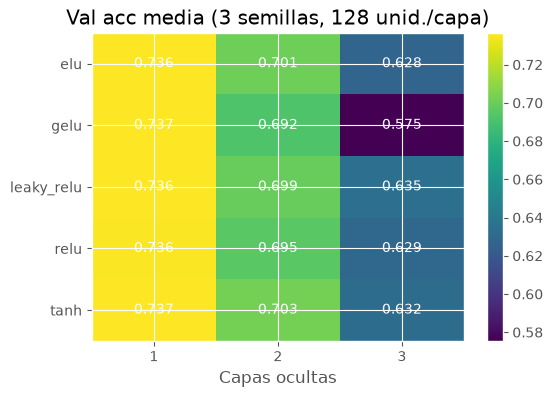

In [25]:
SEEDS = [0, 1, 2]
X_tr, X_val, y_tr, y_val = get_split_features(True, "none", (1, 1), 10000, 1)
g_train = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=128, shuffle=True)
g_val = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=128)

rows = []
for act, nl, seed in itertools.product(ACTIVATIONS, [1, 2, 3], SEEDS):
    torch.manual_seed(seed)
    m = MLP(X_tr.shape[1], NUM_CLASSES, [128] * nl, act, dropout=0.28)
    o = build_optimizer("adam", m.parameters(), lr=5e-4, weight_decay=1e-7)
    t0 = time.time()
    h = train_mlp(m, g_train, g_val, o, epochs=15)
    rows.append(dict(activation=act, n_layers=nl, seed=seed, val_acc=h["val_acc"][-1],
                     train_acc=h["train_acc"][-1], time=time.time() - t0))
    print(f"{act:10s} {nl} capas seed={seed} val={rows[-1]['val_acc']:.4f} {rows[-1]['time']:.0f}s")

grid = pd.DataFrame(rows)
summ = grid.groupby(["activation", "n_layers"]).agg(
    val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
    gap=("train_acc", "mean"), time_s=("time", "mean")).round(4)
print(summ)

# Heatmap de accuracy media
piv = grid.pivot_table(index="activation", columns="n_layers", values="val_acc", aggfunc="mean")
plt.figure(figsize=(6, 4))
plt.imshow(piv.values, cmap="viridis", aspect="auto")
plt.xticks(range(3), piv.columns); plt.yticks(range(len(piv)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        plt.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", color="w")
plt.xlabel("Capas ocultas"); plt.title("Val acc media (3 semillas, 128 unid./capa)")
plt.colorbar(); plt.show()

### Resultados (val accuracy media de 3 semillas)
| Activación | 1 capa | 2 capas | 3 capas |
|---|---|---|---|
| ReLU | 0.736 | 0.695 | 0.629 |
| LeakyReLU | 0.737 | 0.699 | 0.635 |
| tanh | 0.737 | 0.703 | 0.632 |
| GELU | 0.737 | 0.692 | 0.576 |
| ELU | 0.736 | 0.701 | 0.628 |

- **La profundidad es el factor dominante**: pasar de 1 a 3 capas cuesta ~10 puntos de accuracy y aumenta la brecha train–validación, de ~0.2 a ~0.3–0.35.
- **La activación casi no importa.** Con 1 capa las cinco dan 0.736–0.737 con desvíos de 0.002–0.004; con 2 capas las diferencias también quedan dentro del ruido entre semillas. Esto coincide con la baja importancia de `activation` en Optuna.
- **Excepción: GELU con 3 capas** rindió peor (0.576, con las 3 semillas por debajo de las 12 de las otras activaciones). Con solo 3 semillas por celda lo reportamos como observación; la causa no está investigada.
- **El tiempo casi no depende de la profundidad** (~27–33 s en todos los casos) porque con 128 unidades el costo lo domina la primera capa. En la sección 5, en cambio, el tiempo crece al ensanchar la red, lo que confirma que **el ancho de la primera capa es lo que encarece**.
- **Salvedad:** esto no prueba que las redes profundas sean peores en general. Los HPs fijos salieron del mejor modelo de 1 capa, se midió la última época y, como vimos en la sección 5, las redes profundas llegan a su mejor val loss en la época 2. Con early stopping, otro lr o más regularización podrían acercarse. La conclusión válida es: *con los HPs óptimos para 1 capa y 15 épocas, agregar capas empeoró el rendimiento y aumentó el overfitting*.

## 8. Comparación contra softmax con varias semillas

### 8.a. Softmax con el **mismo presupuesto de búsqueda** que el MLP

La comparación original enfrentaba al MLP (60 trials, 15 épocas, optimizador buscado) contra un softmax con 15 trials de 5 épocas (10 en la entrega anterior). Para que la comparación sea justa se tunea el softmax con el **mismo protocolo** que el MLP: **60 trials, 15 épocas, mismo sampler (TPE, semilla 42), mismo `MedianPruner`, mismo split de validación y mismos espacios de preprocesamiento, optimizador (Adam/RMSprop/SGD), lr y weight decay**. Lo único que cambia es la arquitectura: el modelo es una sola capa lineal (sin capas ocultas, ni activación ni dropout).

In [26]:
STORAGE = "sqlite:///mlp_study.db"
SOFTMAX_EQ_TRIALS = 60            # mismo número de trials que el MLP

def objective_softmax_eq(trial):
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_ = (1, 1) if trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"]) == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    lr = trial.suggest_float("lr", 1e-5, 1e-1, log=True)
    wd = trial.suggest_float("weight_decay", 1e-8, 1e-2, log=True)
    kw = {}
    if opt_name == "adam":
        kw["beta1"] = trial.suggest_float("beta1", 0.8, 0.99)
        kw["beta2"] = trial.suggest_float("beta2", 0.9, 0.9999)
    elif opt_name == "rmsprop":
        kw["alpha"] = trial.suggest_float("alpha", 0.9, 0.999)
        kw["momentum"] = trial.suggest_float("rms_momentum", 0.0, 0.9)
    else:
        kw["momentum"] = trial.suggest_float("sgd_momentum", 0.0, 0.99)
        kw["nesterov"] = trial.suggest_categorical("nesterov", [False, True])

    X_tr, X_val, y_tr, y_val = get_split_features(remove_sw, norm, ngram_, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, y_val), batch_size=batch_size, shuffle=False)
    model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES)
    optimizer = build_optimizer(opt_name, model.parameters(), lr, wd, **kw)
    t0 = time.time()
    h = train_mlp(model, train_loader, val_loader, optimizer, EPOCHS_SEARCH, trial=trial)
    trial.set_user_attr("train_time", time.time() - t0)
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))
    trial.set_user_attr("final_train_acc", h["train_acc"][-1])
    return h["val_acc"][-1]

study_softmax_eq = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    study_name="softmax_20newsgroups", storage=STORAGE, load_if_exists=True)
for t in study_softmax_eq.trials:
    if t.state == optuna.trial.TrialState.RUNNING:
        study_softmax_eq.tell(t.number, state=optuna.trial.TrialState.FAIL)
hechos = sum(t.state.is_finished() and t.state.name != "FAIL" for t in study_softmax_eq.trials)
study_softmax_eq.optimize(objective_softmax_eq, n_trials=max(0, SOFTMAX_EQ_TRIALS - hechos))

n_comp = sum(t.state.name == "COMPLETE" for t in study_softmax_eq.trials)
n_pod = sum(t.state.name == "PRUNED" for t in study_softmax_eq.trials)
print(f"Softmax (presupuesto igual): {n_comp} completos / {n_pod} podados")
print("Mejor val acc:", round(study_softmax_eq.best_value, 4), "| Mejor configuración:", study_softmax_eq.best_params)
print(f"Para comparar -> MLP: mejor val acc {study_mlp.best_value:.4f} | Softmax TP1 (15 trials, 5 épocas): {study.best_value:.4f}")
log_study_to_mlflow(study_softmax_eq, "TP2_MLP_busqueda")
mlflow.set_experiment("TP2_MLP")

Softmax (presupuesto igual): 32 completos / 28 podados
Mejor val acc: 0.7247 | Mejor configuración: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'batch_size': 128, 'optimizer': 'adam', 'lr': 0.005101388312226901, 'weight_decay': 1.4854503282244493e-07, 'beta1': 0.8717393474671464, 'beta2': 0.9203206997730125}
Para comparar -> MLP: mejor val acc 0.7371 | Softmax TP1 (15 trials, 5 épocas): 0.7194
softmax_20newsgroups: 60 trials registrados en MLflow (TP2_MLP_busqueda)


<Experiment: artifact_location='file:c:/Users/matia/RedesNeuronales2026/TP2_MLP/mlruns/1', creation_time=1794970567502, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794970567502, lifecycle_stage='active', name='TP2_MLP', tags={}, trace_location=None, workspace='default'>

In [27]:
def make_loaders(p):
    ng = (1, 1) if p["ngram_range"] == "1gram" else (1, 2)
    tr, te = preprocessed_cache[(p["remove_stopwords"], p["normalization"])]
    Xtr, Xte, _ = vectorize_data(tr, te, ng, p["max_features"], p["min_df"])
    return (DataLoader(to_tensor_dataset(Xtr, newsgroups_train.target), batch_size=p["batch_size"], shuffle=True),
            DataLoader(to_tensor_dataset(Xte, newsgroups_test.target), batch_size=p["batch_size"]),
            Xtr.shape[1])

def eval_acc(model, loader):
    model.eval(); c = n = 0
    with torch.no_grad():
        for xb, yb in loader:
            c += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item(); n += len(yb)
    return c / n

def softmax_and_opt_from_params(p, input_dim):
    # Softmax con el optimizador y los hiperparámetros del estudio de presupuesto igual
    model = SoftmaxRegression(input_dim, NUM_CLASSES)
    if p["optimizer"] == "adam":
        kw = dict(beta1=p["beta1"], beta2=p["beta2"])
    elif p["optimizer"] == "rmsprop":
        kw = dict(alpha=p["alpha"], momentum=p["rms_momentum"])
    else:
        kw = dict(momentum=p["sgd_momentum"], nesterov=p["nesterov"])
    return model, build_optimizer(p["optimizer"], model.parameters(), p["lr"], p["weight_decay"], **kw)

N_SEEDS = 5
MODELOS = [
    ("softmax TP1 (15 trials, 5 ép.)", study.best_params, "tp1"),
    ("softmax (60 trials, 15 ép.)", study_softmax_eq.best_params, "eq"),
    ("mlp (60 trials, 15 ép.)", study_mlp.best_params, "mlp"),
]
cmp_rows = []
preds_por_modelo = {}
for name, p, kind in MODELOS:
    trl, tel, d = make_loaders(p)
    for seed in range(N_SEEDS):
        torch.manual_seed(seed)
        if kind == "tp1":
            m = SoftmaxRegression(d, NUM_CLASSES); o = optim.Adam(m.parameters(), lr=p["lr"])
        elif kind == "eq":
            m, o = softmax_and_opt_from_params(p, d)
        else:
            m, o = model_and_opt_from_params(p, d)
        t0 = time.time()
        with mlflow.start_run(run_name=f"{kind}_seed{seed}"):
            mlflow.log_params({"modelo": name, "seed": seed, **{k: v for k, v in p.items()}})
            # val_loader=None: el test no se mira durante el entrenamiento, solo en la evaluación de abajo
            train_mlp(m, trl, None, o, epochs=15, log_mlflow=True)       # sirve para cualquier nn.Module
            t = time.time() - t0
            acc = eval_acc(m, tel)
            mlflow.log_metrics({"test_acc": acc, "tiempo_s": t})
        cmp_rows.append(dict(modelo=name, seed=seed, test_acc=acc, tiempo_s=t,
                             params=sum(q.numel() for q in m.parameters())))
        print(f"{name:32s} seed={seed} test_acc={acc:.4f} {t:.0f}s")

cmp = pd.DataFrame(cmp_rows)
cmp_sum = cmp.groupby("modelo", sort=False).agg(acc_media=("test_acc", "mean"), acc_std=("test_acc", "std"),
                                tiempo_medio_s=("tiempo_s", "mean"), params=("params", "first")).round(4)
print(cmp_sum)


softmax TP1 (15 trials, 5 ép.)   seed=0 test_acc=0.6622 12s
softmax TP1 (15 trials, 5 ép.)   seed=1 test_acc=0.6600 11s
softmax TP1 (15 trials, 5 ép.)   seed=2 test_acc=0.6618 12s
softmax TP1 (15 trials, 5 ép.)   seed=3 test_acc=0.6618 11s
softmax TP1 (15 trials, 5 ép.)   seed=4 test_acc=0.6610 11s
softmax (60 trials, 15 ép.)      seed=0 test_acc=0.6751 11s
softmax (60 trials, 15 ép.)      seed=1 test_acc=0.6767 11s
softmax (60 trials, 15 ép.)      seed=2 test_acc=0.6735 10s
softmax (60 trials, 15 ép.)      seed=3 test_acc=0.6737 11s
softmax (60 trials, 15 ép.)      seed=4 test_acc=0.6753 11s
mlp (60 trials, 15 ép.)          seed=0 test_acc=0.6844 37s
mlp (60 trials, 15 ép.)          seed=1 test_acc=0.6840 38s
mlp (60 trials, 15 ép.)          seed=2 test_acc=0.6865 37s
mlp (60 trials, 15 ép.)          seed=3 test_acc=0.6857 38s
mlp (60 trials, 15 ép.)          seed=4 test_acc=0.6831 37s
                                acc_media  acc_std  tiempo_medio_s   params
modelo                  

### Resultados

In [28]:
cs = cmp.groupby("modelo", sort=False).agg(acc=("test_acc", "mean"), sd=("test_acc", "std"), tmin=("test_acc", "min"), tmax=("test_acc", "max"),
                                           t=("tiempo_s", "mean"), params=("params", "first"))
filas = ["| Modelo | Test acc (media ± desvío, 5 semillas) | Rango | Parámetros | Tiempo (15 épocas) |", "|---|---|---|---|---|"]
for n, r in cs.iterrows():
    filas.append(f"| {n} | {r.acc:.4f} ± {r.sd:.4f} | {r.tmin:.4f}–{r.tmax:.4f} | {int(r.params):,} | {r.t:.0f} s |")
sm_eq, sm_tp1, ml = cs.loc["softmax (60 trials, 15 ép.)"], cs.loc["softmax TP1 (15 trials, 5 ép.)"], cs.loc["mlp (60 trials, 15 ép.)"]
mejor_semilla_sm = cmp[cmp.modelo == "softmax (60 trials, 15 ép.)"].test_acc.max()
peor_semilla_ml = cmp[cmp.modelo == "mlp (60 trials, 15 ép.)"].test_acc.min()
dif = ml.acc - sm_eq.acc
SE_TEST = (0.68 * 0.32 / 7532) ** 0.5
texto = "\n".join(filas) + "\n\n"
texto += (f"- **Con presupuestos iguales** (60 trials, 15 épocas, mismo pruner), el MLP obtiene {ml.acc:.4f} y el softmax {sm_eq.acc:.4f}: diferencia de **{abs(dif) * 100:.2f} puntos a favor del {'MLP' if dif > 0 else 'softmax'}** "
          f"({'la peor semilla del MLP supera a la mejor del softmax' if peor_semilla_ml > mejor_semilla_sm else 'los rangos de las semillas se solapan'}). "
          f"El error estándar del test es de ≈ ±{SE_TEST * 100:.1f} puntos y el desvío entre semillas no incluye esa incertidumbre, así que la diferencia "
          f"{'está en el orden del error del test' if abs(dif) < 2 * SE_TEST else 'supera el error del test'}.\n")
texto += (f"- **Efecto de igualar el presupuesto:** el softmax pasó de {sm_tp1.acc:.4f} (15 trials, 5 épocas, solo Adam y lr) a {sm_eq.acc:.4f} con el protocolo del MLP "
          f"({(sm_eq.acc - sm_tp1.acc) * 100:+.2f} puntos). {'Parte de la ventaja que el MLP mostraba contra el softmax del TP1 se debía a la asimetría de presupuesto.' if sm_eq.acc > sm_tp1.acc and ml.acc > sm_tp1.acc else ('El presupuesto extra no mejoró al softmax en test.' if sm_eq.acc <= sm_tp1.acc else 'El presupuesto extra mejoró al softmax.')}\n")
texto += (f"- **Costo del MLP:** {ml.params / sm_eq.params:.1f} veces más parámetros y {ml.t / sm_eq.t:.1f} veces más tiempo que el softmax de presupuesto igual.\n")
texto += ("- **Salvedades:** ya no hay asimetría de presupuesto, pero el desvío entre semillas no incluye la incertidumbre del conjunto de test; "
          "para afirmar superioridad con más rigor habría que hacer un test pareado (por ejemplo, McNemar) sobre las predicciones.")
display(Markdown(texto))

| Modelo | Test acc (media ± desvío, 5 semillas) | Rango | Parámetros | Tiempo (15 épocas) |
|---|---|---|---|---|
| softmax TP1 (15 trials, 5 ép.) | 0.6614 ± 0.0009 | 0.6600–0.6622 | 200,020 | 11 s |
| softmax (60 trials, 15 ép.) | 0.6749 ± 0.0013 | 0.6735–0.6767 | 200,020 | 11 s |
| mlp (60 trials, 15 ép.) | 0.6848 ± 0.0014 | 0.6831–0.6865 | 1,282,708 | 37 s |

- **Con presupuestos iguales** (60 trials, 15 épocas, mismo pruner), el MLP obtiene 0.6848 y el softmax 0.6749: diferencia de **0.99 puntos a favor del MLP** (la peor semilla del MLP supera a la mejor del softmax). El error estándar del test es de ≈ ±0.5 puntos y el desvío entre semillas no incluye esa incertidumbre, así que la diferencia está en el orden del error del test.
- **Efecto de igualar el presupuesto:** el softmax pasó de 0.6614 (15 trials, 5 épocas, solo Adam y lr) a 0.6749 con el protocolo del MLP (+1.35 puntos). Parte de la ventaja que el MLP mostraba contra el softmax del TP1 se debía a la asimetría de presupuesto.
- **Costo del MLP:** 6.4 veces más parámetros y 3.4 veces más tiempo que el softmax de presupuesto igual.
- **Salvedades:** ya no hay asimetría de presupuesto, pero el desvío entre semillas no incluye la incertidumbre del conjunto de test; para afirmar superioridad con más rigor habría que hacer un test pareado (por ejemplo, McNemar) sobre las predicciones.

# Conclusiones

**1. Activaciones.** En un experimento controlado (sección 7), las cinco activaciones (ReLU, LeakyReLU, tanh, GELU, ELU) rinden igual con 1 y 2 capas, con diferencias dentro del ruido entre semillas. Solo GELU con 3 capas quedó claramente peor. La activación es un hiperparámetro de bajo impacto en este problema.

**2. Profundidad.** Es el factor más influyente: con los HPs óptimos de 1 capa, pasar de 1 a 3 capas bajó la val accuracy ~10 puntos y aumentó el overfitting, sin costo de tiempo relevante. Esto no demuestra que las redes profundas sean peores en general, sino que no mejoran con esta representación (TF-IDF de alta dimensión) y este presupuesto de entrenamiento.

**3. Unidades por capa.** Las redes angostas (64–128 unidades) igualan a las anchas (256–512) en accuracy, y el tiempo crece fuertemente con el ancho de la primera capa. Ensanchar la red no mejora la accuracy y sí aumenta el costo

**4. Optimizadores y momentos.** Adam y RMSprop son indistinguibles en rendimiento y fáciles de configurar. SGD con momentum queda por debajo de ellos con este presupuesto (ver la tabla de 3.b con los 20 trials completos) y es mucho más sensible a lr y momentum: solo funciona con un paso efectivo `lr/(1−momentum)` en un rango acotado. La búsqueda no permitió aislar el efecto de β1/β2 (Adam) ni de α/momentum (RMSprop) dentro de los rangos explorados.

**5. HPs del TP anterior.** El learning rate sigue siendo un hiperparámetro crítico. El mejor MLP y el mejor softmax coinciden en usar unigramas y un vocabulario de 10000 features, pero difieren en la eliminación de stopwords (el MLP las remueve, el softmax de la Parte 1 no), en la normalización (lematización en softmax, ninguna en el MLP) y en `min_df` (2 contra 1). Esta búsqueda no permite medir el efecto de cada uno por separado, y las diferencias de normalización entre los mejores trials están dentro del ruido.

**6. Overfitting.** Se consigue con 3×1024 o 3×2048 sin regularización: train accuracy en el techo (0.973) y val loss creciente desde la época 2. Ese techo es un límite del dataset (documentos vacíos y duplicados con etiquetas distintas), no de la red. El problema se sobreajusta incluso con 1×64.

**7. Rendimiento y tiempos.** Más parámetros no dieron mejor accuracy y cuestan mucho más tiempo (de 30 s a 942 s al pasar de 1×64 a 3×2048). El mejor MLP rinde ~0.685 en test (media de 5 semillas), unos 5 puntos menos que en validación (0.737), caída que también aparece en el softmax (0.719 → 0.659 en la Parte 1).

**8. Pruning.** Descartó una parte importante de los trials a bajo costo (porcentajes por estudio en 3.b y 6). El ahorro total fue de ~19 % en la búsqueda principal (estimación aproximada), modesto porque TPE ya evitaba las zonas malas.

**9. MLP vs softmax.** Con **presupuestos de búsqueda iguales** (60 trials, 15 épocas, mismo pruner), el MLP obtiene 0.6848 ± 0.0014 en test y el softmax 0.6749 ± 0.0013 (5 semillas): una diferencia de ~1 punto a favor del MLP, del orden del error estándar del test (±0.5 puntos). El softmax del TP1 (15 trials, 5 épocas) llegaba a 0.6614, así que ~1.35 puntos de la ventaja aparente del MLP se debían al presupuesto de búsqueda. La regresión softmax sobre TF-IDF es un baseline muy competitivo: la mejora del MLP es chica (~1 punto) frente a su costo (6.4× parámetros y 3.4× tiempo).

**10. Regularización, épocas y rangos.** En 6.c, con un experimento controlado, se aísla el efecto de dropout y de weight decay (incluyendo la variante sin decay en los bias y max-norm). En 4.b el número de épocas se elige con validación y se justifica el uso de 15, y en 3.c se muestra que acotar los rangos de lr y weight decay vuelve más eficiente la búsqueda con un mejor valor equivalente (0.743 contra 0.737, dentro del error) pero más trials útiles; la ventaja es de eficiencia, no de un mejor óptimo.

**Limitaciones.** (a) Muchas diferencias están dentro del error de estimación de la validación (~±0.9 puntos). (b) TPE concentra los trials y desbalancea los grupos, por eso las comparaciones de factores se hicieron con experimentos controlados. (c) El estudio de SGD, interrumpido en la entrega anterior, se completó hasta 20 trials como los otros dos. (d) Los resultados dependen del entorno (CPU), así que los tiempos son relativos. (e) Softmax y MLP tienen el mismo presupuesto de búsqueda (60 trials, 15 épocas); el `objective` usa la val accuracy de la última época sin early stopping (ver 3.a), por lo que la "mejor configuración" es la mejor a 15 épocas. (f) El experimento 6.c usa solo 2 semillas.